In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

from torchvision import datasets
from torchvision.models import vgg16, VGG16_Weights

from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

print("\nCUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU Memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")
else:
    print("WARNING: GPU not available. Training will use CPU.")

PyTorch: 2.15.0+cu132
Torchvision: 0.29.2+cu132

CUDA Available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
GPU Memory: 8.0 GB


In [2]:
# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Project paths
PROJECT_DIR = Path.cwd().parent

DATASET_DIR = PROJECT_DIR / "notebooks" / "dataset" / "processed_dataset"
PREPROCESSING_DIR = PROJECT_DIR / "notebooks" / "research-notes" / "preprocessing"

MODEL_DIR = PROJECT_DIR / "models" / "vgg16"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Experiment configuration
IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_CLASSES = 2

NUM_EPOCHS_HEAD = 10
NUM_EPOCHS_FINETUNE = 40
TOTAL_MAX_EPOCHS = 50

LEARNING_RATE_HEAD = 1e-3
LEARNING_RATE_FINETUNE = 1e-4
WEIGHT_DECAY = 1e-4

COLOR_SPACES = ["RGB", "HSV", "YCgCr"]
CLASS_NAMES = ["Ripe", "Unripe"]

EARLY_STOPPING_PATIENCE = 5

print("VGG16 EXPERIMENT CONFIGURATION")
print("=" * 45)
print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATASET_DIR)
print("Model directory:", MODEL_DIR)
print("Device:", DEVICE)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", TOTAL_MAX_EPOCHS)
print("Color spaces:", COLOR_SPACES)

assert DATASET_DIR.exists(), f"Dataset not found: {DATASET_DIR}"
assert PREPROCESSING_DIR.exists(), f"Preprocessing folder not found: {PREPROCESSING_DIR}"

print("\nConfiguration verified.")

VGG16 EXPERIMENT CONFIGURATION
Project directory: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter
Dataset directory: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\notebooks\dataset\processed_dataset
Model directory: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\vgg16
Device: cuda
Image size: 224
Batch size: 16
Maximum epochs: 50
Color spaces: ['RGB', 'HSV', 'YCgCr']

Configuration verified.


In [3]:
import json

STATS_PATH = PREPROCESSING_DIR / "normalization_stats.json"

with open(STATS_PATH, "r") as f:
    normalization_stats = json.load(f)

print("NORMALIZATION STATISTICS")
print("=" * 45)

for color_space in COLOR_SPACES:
    mean = normalization_stats[color_space]["mean"]
    std = normalization_stats[color_space]["std"]

    print(f"\n{color_space}")
    print("Mean:", mean)
    print("Std :", std)

    assert len(mean) == 3
    assert len(std) == 3
    assert all(s > 0 for s in std)

print("\nAll normalization statistics verified.")

NORMALIZATION STATISTICS

RGB
Mean: [0.3409183707365453, 0.31965236125256286, 0.246347647622037]
Std : [0.3073407603064623, 0.2990722908867604, 0.2818262994987366]

HSV
Mean: [0.1791005163545884, 0.2921350788579354, 0.3535657906756214]
Std : [0.23581772780670712, 0.28432641901263034, 0.31211639141326053]

YCgCr
Mean: [0.30671704291596547, 0.5135682372747012, 0.5478768622983937]
Std : [0.29169941609069794, 0.026401596916654203, 0.06957786056603277]

All normalization statistics verified.


In [4]:
def get_transforms(color_space):

    mean = normalization_stats[color_space]["mean"]
    std = normalization_stats[color_space]["std"]

    train_transform = transforms.Compose([
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(
            degrees=10,
            interpolation=transforms.InterpolationMode.BILINEAR,
            fill=tuple(round(x * 255) for x in mean)
        ),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std)
    ])

    eval_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std)
    ])

    return train_transform, eval_transform


def build_dataloaders(color_space):

    color_dir = DATASET_DIR / color_space

    train_transform, eval_transform = get_transforms(color_space)

    train_dataset = datasets.ImageFolder(
        color_dir / "train",
        transform=train_transform
    )

    val_dataset = datasets.ImageFolder(
        color_dir / "validation",
        transform=eval_transform
    )

    test_dataset = datasets.ImageFolder(
        color_dir / "test",
        transform=eval_transform
    )

    assert train_dataset.class_to_idx == {
        "Ripe": 0, "Unripe": 1
    }

    loader_kwargs = {
        "batch_size": BATCH_SIZE,
        "num_workers": 0,
        "pin_memory": torch.cuda.is_available()
    }

    train_loader = DataLoader(
        train_dataset,
        shuffle=True,
        **loader_kwargs
    )

    val_loader = DataLoader(
        val_dataset,
        shuffle=False,
        **loader_kwargs
    )

    test_loader = DataLoader(
        test_dataset,
        shuffle=False,
        **loader_kwargs
    )

    return train_loader, val_loader, test_loader


# Build all three color-space loaders
dataloaders = {}

for color_space in COLOR_SPACES:

    train_loader, val_loader, test_loader = build_dataloaders(color_space)

    dataloaders[color_space] = {
        "train": train_loader,
        "validation": val_loader,
        "test": test_loader
    }

    print(f"\n{color_space}")
    print("Training:", len(train_loader.dataset))
    print("Validation:", len(val_loader.dataset))
    print("Testing:", len(test_loader.dataset))
    print("Class mapping:", train_loader.dataset.class_to_idx)

print("\nAll VGG16 dataloaders created.")


RGB
Training: 558
Validation: 69
Testing: 70
Class mapping: {'Ripe': 0, 'Unripe': 1}

HSV
Training: 558
Validation: 69
Testing: 70
Class mapping: {'Ripe': 0, 'Unripe': 1}

YCgCr
Training: 558
Validation: 69
Testing: 70
Class mapping: {'Ripe': 0, 'Unripe': 1}

All VGG16 dataloaders created.


In [5]:
from torchvision.models import vgg16, VGG16_Weights

def build_vgg16(freeze_backbone=True):

    # Load ImageNet pretrained VGG16
    model = vgg16(weights=VGG16_Weights.IMAGENET1K_V1)

    # Freeze convolutional feature extractor
    if freeze_backbone:
        for param in model.features.parameters():
            param.requires_grad = False

    # Replace final classification layer
    in_features = model.classifier[6].in_features
    model.classifier[6] = nn.Linear(in_features, NUM_CLASSES)

    return model.to(DEVICE)


# Initialize model
model = build_vgg16(freeze_backbone=True)

# Verify architecture
print(model.classifier)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("\nVGG16 MODEL SUMMARY")
print("=" * 40)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

# Verify output dimensions
dummy_input = torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE).to(DEVICE)

with torch.no_grad():
    output = model(dummy_input)

print("\nInput shape:", dummy_input.shape)
print("Output shape:", output.shape)

assert output.shape == (2, NUM_CLASSES)

print("\nVGG16 initialization successful.")

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to C:\Users\gsama/.cache\torch\hub\checkpoints\vgg16-397923af.pth


100%|██████████| 528M/528M [01:28<00:00, 6.26MB/s] 


Sequential(
  (0): Linear(in_features=25088, out_features=4096, bias=True)
  (1): ReLU(inplace=True)
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=4096, out_features=4096, bias=True)
  (4): ReLU(inplace=True)
  (5): Dropout(p=0.5, inplace=False)
  (6): Linear(in_features=4096, out_features=2, bias=True)
)

VGG16 MODEL SUMMARY
Total parameters: 134,268,738
Trainable parameters: 119,554,050
Frozen parameters: 14,714,688

Input shape: torch.Size([2, 3, 224, 224])
Output shape: torch.Size([2, 2])

VGG16 initialization successful.


In [6]:
# Training configuration
from copy import deepcopy
import time
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Phase 1: Train classifier only
for param in model.features.parameters():
    param.requires_grad = False

for param in model.classifier.parameters():
    param.requires_grad = True

print("PHASE 1 — CLASSIFIER TRAINING")
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

# Check GPU memory
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    allocated = torch.cuda.memory_allocated() / (1024 ** 3)
    reserved = torch.cuda.memory_reserved() / (1024 ** 3)

    print(f"\nGPU: {torch.cuda.get_device_name(0)}")
    print(f"Allocated memory: {allocated:.2f} GB")
    print(f"Reserved memory: {reserved:.2f} GB")

print("\nTraining configuration:")
print("Phase 1 epochs:", NUM_EPOCHS_HEAD)
print("Phase 2 maximum epochs:", NUM_EPOCHS_FINETUNE)
print("Batch size:", BATCH_SIZE)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)

PHASE 1 — CLASSIFIER TRAINING
Trainable parameters: 119554050

GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Allocated memory: 0.50 GB
Reserved memory: 0.51 GB

Training configuration:
Phase 1 epochs: 10
Phase 2 maximum epochs: 40
Batch size: 16
Early stopping patience: 5


c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None

    model.train() if is_training else model.eval()

    # Keep frozen feature extractor in evaluation mode
    if is_training:
        for param in model.features.parameters():
            if not param.requires_grad:
                model.features.eval()

    running_loss = 0.0
    all_labels = []
    all_predictions = []

    for images, labels in tqdm(loader, leave=False, disable=True):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            outputs = model(images)
            loss = criterion(outputs, labels)

            if is_training:
                loss.backward()
                optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)
        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_accuracy = accuracy_score(all_labels, all_predictions)
    epoch_macro_f1 = f1_score(
        all_labels, all_predictions, average="macro", zero_division=0
    )

    return {
        "loss": epoch_loss,
        "accuracy": epoch_accuracy,
        "macro_f1": epoch_macro_f1
    }


print("Training and validation functions defined successfully.")

Training and validation functions defined successfully.


In [8]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE_HEAD,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

print("OPTIMIZER CONFIGURATION")
print("=" * 40)
print("Optimizer:", optimizer.__class__.__name__)
print("Phase 1 learning rate:", optimizer.param_groups[0]["lr"])
print("Weight decay:", WEIGHT_DECAY)
print("Scheduler:", scheduler.__class__.__name__)
print("Scheduler patience:", scheduler.patience)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)

OPTIMIZER CONFIGURATION
Optimizer: AdamW
Phase 1 learning rate: 0.001
Weight decay: 0.0001
Scheduler: ReduceLROnPlateau
Scheduler patience: 2
Early stopping patience: 5


In [9]:
# Training history
history = {
    "train_loss": [],
    "train_accuracy": [],
    "train_macro_f1": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": [],
    "learning_rate": []
}

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

best_model_state = None

CHECKPOINT_PATH = MODEL_DIR / "vgg16_RGB_best.pth"

print("CHECKPOINT CONFIGURATION")
print("=" * 40)
print("Checkpoint path:", CHECKPOINT_PATH)
print("Selection metric: Validation loss")
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)
print("Initial best validation loss:", best_val_loss)

CHECKPOINT CONFIGURATION
Checkpoint path: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\vgg16\vgg16_RGB_best.pth
Selection metric: Validation loss
Early stopping patience: 5
Initial best validation loss: inf


In [13]:
print("Starting VGG16 — RGB Phase 1")
print("=" * 60)

for epoch in range(NUM_EPOCHS_HEAD):
    start_time = time.time()

    train_metrics = run_epoch(
        model, train_loader, criterion, optimizer
    )

    val_metrics = run_epoch(
        model, val_loader, criterion
    )

    scheduler.step(val_metrics["loss"])

    current_lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(train_metrics["loss"])
    history["train_accuracy"].append(train_metrics["accuracy"])
    history["train_macro_f1"].append(train_metrics["macro_f1"])
    history["val_loss"].append(val_metrics["loss"])
    history["val_accuracy"].append(val_metrics["accuracy"])
    history["val_macro_f1"].append(val_metrics["macro_f1"])
    history["learning_rate"].append(current_lr)

    if val_metrics["loss"] < best_val_loss:
        best_val_loss = val_metrics["loss"]
        best_epoch = epoch + 1
        epochs_without_improvement = 0
        best_model_state = deepcopy(model.state_dict())

        torch.save({
            "epoch": best_epoch,
            "model_state_dict": best_model_state,
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "color_space": "RGB"
        }, CHECKPOINT_PATH)

        status = "BEST MODEL SAVED"
    else:
        epochs_without_improvement += 1
        status = f"No improvement ({epochs_without_improvement}/5)"

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch+1:02d}/{NUM_EPOCHS_HEAD} | "
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Train Acc: {train_metrics['accuracy']*100:.2f}% | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val Acc: {val_metrics['accuracy']*100:.2f}% | "
        f"Val F1: {val_metrics['macro_f1']:.4f} | "
        f"LR: {current_lr:.2e} | "
        f"{elapsed:.1f}s | {status}"
    )

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("\nEarly stopping triggered.")
        break

print("\nPhase 1 completed.")
print("Best validation loss:", round(best_val_loss, 4))
print("Best epoch:", best_epoch)

Starting VGG16 — RGB Phase 1
Epoch 01/10 | Train Loss: 1.4901 | Train Acc: 56.09% | Val Loss: 0.8170 | Val Acc: 63.77% | Val F1: 0.3894 | LR: 1.00e-03 | 8.9s | BEST MODEL SAVED
Epoch 02/10 | Train Loss: 0.7248 | Train Acc: 68.10% | Val Loss: 0.4874 | Val Acc: 81.16% | Val F1: 0.7903 | LR: 1.00e-03 | 8.1s | BEST MODEL SAVED
Epoch 03/10 | Train Loss: 0.6060 | Train Acc: 75.45% | Val Loss: 0.4789 | Val Acc: 82.61% | Val F1: 0.8118 | LR: 1.00e-03 | 8.1s | BEST MODEL SAVED
Epoch 04/10 | Train Loss: 0.5476 | Train Acc: 77.96% | Val Loss: 0.7524 | Val Acc: 78.26% | Val F1: 0.7398 | LR: 1.00e-03 | 6.2s | No improvement (1/5)
Epoch 05/10 | Train Loss: 0.5819 | Train Acc: 80.82% | Val Loss: 0.8194 | Val Acc: 75.36% | Val F1: 0.7483 | LR: 1.00e-03 | 5.8s | No improvement (2/5)
Epoch 06/10 | Train Loss: 0.6136 | Train Acc: 80.29% | Val Loss: 0.7536 | Val Acc: 76.81% | Val F1: 0.7621 | LR: 5.00e-04 | 5.9s | No improvement (3/5)
Epoch 07/10 | Train Loss: 0.2986 | Train Acc: 88.71% | Val Loss: 0.7706

In [14]:
# Restore the best Phase 1 checkpoint
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])

# Freeze all convolutional layers first
for param in model.features.parameters():
    param.requires_grad = False

# Unfreeze the final convolutional block
for param in model.features[24:].parameters():
    param.requires_grad = True

# Keep the classifier trainable
for param in model.classifier.parameters():
    param.requires_grad = True

# Reinitialize optimizer for fine-tuning
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE_FINETUNE,
    weight_decay=WEIGHT_DECAY
)

# Reset scheduler for Phase 2
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

# Reset early stopping counter
epochs_without_improvement = 0

print("PHASE 2 — FINE-TUNING READY")
print("=" * 45)
print("Restored checkpoint epoch:", checkpoint["epoch"])
print("Restored validation loss:", checkpoint["best_val_loss"])
print("Fine-tuning learning rate:", optimizer.param_groups[0]["lr"])
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Frozen parameters:",
      sum(p.numel() for p in model.parameters() if not p.requires_grad))

PHASE 2 — FINE-TUNING READY
Restored checkpoint epoch: 3
Restored validation loss: 0.478887465984925
Fine-tuning learning rate: 0.0001
Trainable parameters: 126633474
Frozen parameters: 7635264


In [15]:
print("Starting VGG16 — RGB Phase 2")
print("=" * 65)

for epoch in range(NUM_EPOCHS_FINETUNE):
    start_time = time.time()

    train_metrics = run_epoch(
        model, train_loader, criterion, optimizer
    )

    val_metrics = run_epoch(
        model, val_loader, criterion
    )

    scheduler.step(val_metrics["loss"])

    current_lr = optimizer.param_groups[0]["lr"]
    combined_epoch = NUM_EPOCHS_HEAD + epoch + 1

    history["train_loss"].append(train_metrics["loss"])
    history["train_accuracy"].append(train_metrics["accuracy"])
    history["train_macro_f1"].append(train_metrics["macro_f1"])
    history["val_loss"].append(val_metrics["loss"])
    history["val_accuracy"].append(val_metrics["accuracy"])
    history["val_macro_f1"].append(val_metrics["macro_f1"])
    history["learning_rate"].append(current_lr)

    if val_metrics["loss"] < best_val_loss:
        best_val_loss = val_metrics["loss"]
        best_epoch = combined_epoch
        epochs_without_improvement = 0
        best_model_state = deepcopy(model.state_dict())

        torch.save({
            "epoch": best_epoch,
            "phase": 2,
            "model_state_dict": best_model_state,
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "color_space": "RGB"
        }, CHECKPOINT_PATH)

        status = "BEST MODEL SAVED"
    else:
        epochs_without_improvement += 1
        status = f"No improvement ({epochs_without_improvement}/5)"

    elapsed = time.time() - start_time

    print(
        f"Epoch {combined_epoch:02d}/50 | "
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Train Acc: {train_metrics['accuracy']*100:.2f}% | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val Acc: {val_metrics['accuracy']*100:.2f}% | "
        f"Val F1: {val_metrics['macro_f1']:.4f} | "
        f"LR: {current_lr:.2e} | "
        f"{elapsed:.1f}s | {status}"
    )

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("\nEarly stopping triggered.")
        break

print("\nRGB training completed.")
print("Best validation loss:", round(best_val_loss, 4))
print("Best combined epoch:", best_epoch)

Starting VGG16 — RGB Phase 2
Epoch 11/50 | Train Loss: 0.3941 | Train Acc: 84.41% | Val Loss: 0.4017 | Val Acc: 82.61% | Val F1: 0.7998 | LR: 1.00e-04 | 8.5s | BEST MODEL SAVED
Epoch 12/50 | Train Loss: 0.2121 | Train Acc: 91.94% | Val Loss: 0.5246 | Val Acc: 84.06% | Val F1: 0.8225 | LR: 1.00e-04 | 6.2s | No improvement (1/5)
Epoch 13/50 | Train Loss: 0.2001 | Train Acc: 92.47% | Val Loss: 0.3931 | Val Acc: 86.96% | Val F1: 0.8576 | LR: 1.00e-04 | 7.7s | BEST MODEL SAVED
Epoch 14/50 | Train Loss: 0.2227 | Train Acc: 91.58% | Val Loss: 0.3295 | Val Acc: 84.06% | Val F1: 0.8337 | LR: 1.00e-04 | 7.7s | BEST MODEL SAVED
Epoch 15/50 | Train Loss: 0.1055 | Train Acc: 96.24% | Val Loss: 0.5038 | Val Acc: 85.51% | Val F1: 0.8432 | LR: 1.00e-04 | 6.1s | No improvement (1/5)
Epoch 16/50 | Train Loss: 0.1087 | Train Acc: 96.59% | Val Loss: 1.1057 | Val Acc: 84.06% | Val F1: 0.8034 | LR: 1.00e-04 | 6.0s | No improvement (2/5)
Epoch 17/50 | Train Loss: 0.1245 | Train Acc: 96.59% | Val Loss: 0.5151

In [16]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("RGB BEST CHECKPOINT VERIFICATION")
print("=" * 45)
print("Color space:", checkpoint["color_space"])
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])
print("Checkpoint exists:", CHECKPOINT_PATH.exists())
print("Model loaded successfully:", True)

RGB BEST CHECKPOINT VERIFICATION
Color space: RGB
Best epoch: 14
Best validation loss: 0.32949247826700623
Checkpoint exists: True
Model loaded successfully: True


In [17]:
print("Available DataLoader structure:")
for key, value in dataloaders.items():
    print(f"\n{key}:")
    if isinstance(value, dict):
        for split, loader in value.items():
            print(f"  {split}: {type(loader).__name__}, "
                  f"{len(loader.dataset)} images")
    else:
        print(" ", type(value).__name__)

Available DataLoader structure:

RGB:
  train: DataLoader, 558 images
  validation: DataLoader, 69 images
  test: DataLoader, 70 images

HSV:
  train: DataLoader, 558 images
  validation: DataLoader, 69 images
  test: DataLoader, 70 images

YCgCr:
  train: DataLoader, 558 images
  validation: DataLoader, 69 images
  test: DataLoader, 70 images


In [19]:
# Reset random seeds for reproducible classifier initialization
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Select HSV DataLoaders
train_loader = dataloaders["HSV"]["train"]
val_loader = dataloaders["HSV"]["validation"]
test_loader = dataloaders["HSV"]["test"]

# Initialize a fresh VGG16
model = build_vgg16(freeze_backbone=True)

# Reset Phase 1 optimizer and scheduler
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE_HEAD,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

# Fresh HSV experiment tracking
history = {
    "train_loss": [],
    "train_accuracy": [],
    "train_macro_f1": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": [],
    "learning_rate": []
}

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0
best_model_state = None

CHECKPOINT_PATH = MODEL_DIR / "vgg16_HSV_best.pth"

print("HSV EXPERIMENT INITIALIZED")
print("=" * 45)
print("Training images:", len(train_loader.dataset))
print("Validation images:", len(val_loader.dataset))
print("Test images:", len(test_loader.dataset))
print("Checkpoint:", CHECKPOINT_PATH)
print("Initial learning rate:", optimizer.param_groups[0]["lr"])
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

HSV EXPERIMENT INITIALIZED
Training images: 558
Validation images: 69
Test images: 70
Checkpoint: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\vgg16\vgg16_HSV_best.pth
Initial learning rate: 0.001
Trainable parameters: 119554050


In [20]:
print("Starting VGG16 — HSV Phase 1")
print("=" * 60)

for epoch in range(NUM_EPOCHS_HEAD):
    start_time = time.time()

    train_metrics = run_epoch(
        model, train_loader, criterion, optimizer
    )

    val_metrics = run_epoch(
        model, val_loader, criterion
    )

    scheduler.step(val_metrics["loss"])

    current_lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(train_metrics["loss"])
    history["train_accuracy"].append(train_metrics["accuracy"])
    history["train_macro_f1"].append(train_metrics["macro_f1"])
    history["val_loss"].append(val_metrics["loss"])
    history["val_accuracy"].append(val_metrics["accuracy"])
    history["val_macro_f1"].append(val_metrics["macro_f1"])
    history["learning_rate"].append(current_lr)

    if val_metrics["loss"] < best_val_loss:
        best_val_loss = val_metrics["loss"]
        best_epoch = epoch + 1
        epochs_without_improvement = 0
        best_model_state = deepcopy(model.state_dict())

        torch.save({
            "epoch": best_epoch,
            "phase": 1,
            "model_state_dict": best_model_state,
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "color_space": "HSV"
        }, CHECKPOINT_PATH)

        status = "BEST MODEL SAVED"
    else:
        epochs_without_improvement += 1
        status = f"No improvement ({epochs_without_improvement}/5)"

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch+1:02d}/10 | "
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Train Acc: {train_metrics['accuracy']*100:.2f}% | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val Acc: {val_metrics['accuracy']*100:.2f}% | "
        f"Val F1: {val_metrics['macro_f1']:.4f} | "
        f"LR: {current_lr:.2e} | "
        f"{elapsed:.1f}s | {status}"
    )

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("\nEarly stopping triggered.")
        break

print("\nHSV Phase 1 completed.")
print("Best validation loss:", round(best_val_loss, 4))
print("Best epoch:", best_epoch)


Starting VGG16 — HSV Phase 1
Epoch 01/10 | Train Loss: 1.4626 | Train Acc: 58.78% | Val Loss: 0.5882 | Val Acc: 72.46% | Val F1: 0.7225 | LR: 1.00e-03 | 8.3s | BEST MODEL SAVED
Epoch 02/10 | Train Loss: 0.8460 | Train Acc: 63.44% | Val Loss: 0.6132 | Val Acc: 72.46% | Val F1: 0.6492 | LR: 1.00e-03 | 6.2s | No improvement (1/5)
Epoch 03/10 | Train Loss: 0.7320 | Train Acc: 65.05% | Val Loss: 0.5627 | Val Acc: 72.46% | Val F1: 0.7209 | LR: 1.00e-03 | 8.2s | BEST MODEL SAVED
Epoch 04/10 | Train Loss: 0.6839 | Train Acc: 71.51% | Val Loss: 0.7194 | Val Acc: 78.26% | Val F1: 0.7527 | LR: 1.00e-03 | 6.5s | No improvement (1/5)
Epoch 05/10 | Train Loss: 0.6381 | Train Acc: 74.37% | Val Loss: 0.6954 | Val Acc: 78.26% | Val F1: 0.7527 | LR: 1.00e-03 | 6.1s | No improvement (2/5)
Epoch 06/10 | Train Loss: 0.5937 | Train Acc: 76.70% | Val Loss: 0.5365 | Val Acc: 75.36% | Val F1: 0.7396 | LR: 1.00e-03 | 7.8s | BEST MODEL SAVED
Epoch 07/10 | Train Loss: 0.6826 | Train Acc: 75.81% | Val Loss: 0.5610

In [21]:
# Restore best Phase 1 HSV checkpoint
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])

# Freeze all convolutional layers
for param in model.features.parameters():
    param.requires_grad = False

# Unfreeze the final convolutional block
for param in model.features[24:].parameters():
    param.requires_grad = True

# Keep classifier trainable
for param in model.classifier.parameters():
    param.requires_grad = True

# Configure Phase 2 optimizer
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE_FINETUNE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

epochs_without_improvement = 0

print("HSV PHASE 2 — FINE-TUNING READY")
print("=" * 45)
print("Restored checkpoint epoch:", checkpoint["epoch"])
print("Restored validation loss:", checkpoint["best_val_loss"])
print("Fine-tuning learning rate:", optimizer.param_groups[0]["lr"])
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Frozen parameters:",
      sum(p.numel() for p in model.parameters() if not p.requires_grad))

HSV PHASE 2 — FINE-TUNING READY
Restored checkpoint epoch: 9
Restored validation loss: 0.5136250522851512
Fine-tuning learning rate: 0.0001
Trainable parameters: 126633474
Frozen parameters: 7635264


In [22]:
print("Starting VGG16 — HSV Phase 2")
print("=" * 65)

for epoch in range(NUM_EPOCHS_FINETUNE):
    start_time = time.time()

    train_metrics = run_epoch(
        model, train_loader, criterion, optimizer
    )

    val_metrics = run_epoch(
        model, val_loader, criterion
    )

    scheduler.step(val_metrics["loss"])

    current_lr = optimizer.param_groups[0]["lr"]
    combined_epoch = NUM_EPOCHS_HEAD + epoch + 1

    history["train_loss"].append(train_metrics["loss"])
    history["train_accuracy"].append(train_metrics["accuracy"])
    history["train_macro_f1"].append(train_metrics["macro_f1"])
    history["val_loss"].append(val_metrics["loss"])
    history["val_accuracy"].append(val_metrics["accuracy"])
    history["val_macro_f1"].append(val_metrics["macro_f1"])
    history["learning_rate"].append(current_lr)

    if val_metrics["loss"] < best_val_loss:
        best_val_loss = val_metrics["loss"]
        best_epoch = combined_epoch
        epochs_without_improvement = 0
        best_model_state = deepcopy(model.state_dict())

        torch.save({
            "epoch": best_epoch,
            "phase": 2,
            "model_state_dict": best_model_state,
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "color_space": "HSV"
        }, CHECKPOINT_PATH)

        status = "BEST MODEL SAVED"
    else:
        epochs_without_improvement += 1
        status = f"No improvement ({epochs_without_improvement}/5)"

    elapsed = time.time() - start_time

    print(
        f"Epoch {combined_epoch:02d}/50 | "
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Train Acc: {train_metrics['accuracy']*100:.2f}% | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val Acc: {val_metrics['accuracy']*100:.2f}% | "
        f"Val F1: {val_metrics['macro_f1']:.4f} | "
        f"LR: {current_lr:.2e} | "
        f"{elapsed:.1f}s | {status}"
    )

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("\nEarly stopping triggered.")
        break

print("\nHSV training completed.")
print("Best validation loss:", round(best_val_loss, 4))
print("Best combined epoch:", best_epoch)

Starting VGG16 — HSV Phase 2
Epoch 11/50 | Train Loss: 0.4376 | Train Acc: 80.82% | Val Loss: 0.4634 | Val Acc: 78.26% | Val F1: 0.7733 | LR: 1.00e-04 | 8.6s | BEST MODEL SAVED
Epoch 12/50 | Train Loss: 0.2681 | Train Acc: 89.96% | Val Loss: 0.4661 | Val Acc: 73.91% | Val F1: 0.7295 | LR: 1.00e-04 | 6.2s | No improvement (1/5)
Epoch 13/50 | Train Loss: 0.2062 | Train Acc: 92.29% | Val Loss: 0.5521 | Val Acc: 78.26% | Val F1: 0.7810 | LR: 1.00e-04 | 6.2s | No improvement (2/5)
Epoch 14/50 | Train Loss: 0.2163 | Train Acc: 92.47% | Val Loss: 0.5799 | Val Acc: 79.71% | Val F1: 0.7536 | LR: 5.00e-05 | 7.3s | No improvement (3/5)
Epoch 15/50 | Train Loss: 0.1597 | Train Acc: 95.16% | Val Loss: 0.4646 | Val Acc: 84.06% | Val F1: 0.8260 | LR: 5.00e-05 | 7.4s | No improvement (4/5)
Epoch 16/50 | Train Loss: 0.0871 | Train Acc: 96.59% | Val Loss: 0.6482 | Val Acc: 81.16% | Val F1: 0.7804 | LR: 5.00e-05 | 6.5s | No improvement (5/5)

Early stopping triggered.

HSV training completed.
Best valida

In [23]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("HSV BEST CHECKPOINT VERIFICATION")
print("=" * 45)
print("Color space:", checkpoint["color_space"])
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])
print("Checkpoint exists:", CHECKPOINT_PATH.exists())
print("Model loaded successfully:", True)

HSV BEST CHECKPOINT VERIFICATION
Color space: HSV
Best epoch: 11
Best validation loss: 0.46335573386454926
Checkpoint exists: True
Model loaded successfully: True


In [24]:
# Reset random seeds
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Select YCgCr DataLoaders
train_loader = dataloaders["YCgCr"]["train"]
val_loader = dataloaders["YCgCr"]["validation"]
test_loader = dataloaders["YCgCr"]["test"]

# Initialize fresh VGG16
model = build_vgg16(freeze_backbone=True)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE_HEAD,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

# Fresh experiment history
history = {
    "train_loss": [],
    "train_accuracy": [],
    "train_macro_f1": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": [],
    "learning_rate": []
}

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0
best_model_state = None

CHECKPOINT_PATH = MODEL_DIR / "vgg16_YCgCr_best.pth"

print("YCgCr EXPERIMENT INITIALIZED")
print("=" * 45)
print("Training images:", len(train_loader.dataset))
print("Validation images:", len(val_loader.dataset))
print("Test images:", len(test_loader.dataset))
print("Checkpoint:", CHECKPOINT_PATH)
print("Initial learning rate:", optimizer.param_groups[0]["lr"])
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

YCgCr EXPERIMENT INITIALIZED
Training images: 558
Validation images: 69
Test images: 70
Checkpoint: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\vgg16\vgg16_YCgCr_best.pth
Initial learning rate: 0.001
Trainable parameters: 119554050


In [25]:
print("Starting VGG16 — YCgCr Phase 1")
print("=" * 60)

for epoch in range(NUM_EPOCHS_HEAD):
    start_time = time.time()

    train_metrics = run_epoch(
        model, train_loader, criterion, optimizer
    )

    val_metrics = run_epoch(
        model, val_loader, criterion
    )

    scheduler.step(val_metrics["loss"])

    current_lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(train_metrics["loss"])
    history["train_accuracy"].append(train_metrics["accuracy"])
    history["train_macro_f1"].append(train_metrics["macro_f1"])
    history["val_loss"].append(val_metrics["loss"])
    history["val_accuracy"].append(val_metrics["accuracy"])
    history["val_macro_f1"].append(val_metrics["macro_f1"])
    history["learning_rate"].append(current_lr)

    if val_metrics["loss"] < best_val_loss:
        best_val_loss = val_metrics["loss"]
        best_epoch = epoch + 1
        epochs_without_improvement = 0
        best_model_state = deepcopy(model.state_dict())

        torch.save({
            "epoch": best_epoch,
            "phase": 1,
            "model_state_dict": best_model_state,
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "color_space": "YCgCr"
        }, CHECKPOINT_PATH)

        status = "BEST MODEL SAVED"
    else:
        epochs_without_improvement += 1
        status = f"No improvement ({epochs_without_improvement}/5)"

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch+1:02d}/10 | "
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Train Acc: {train_metrics['accuracy']*100:.2f}% | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val Acc: {val_metrics['accuracy']*100:.2f}% | "
        f"Val F1: {val_metrics['macro_f1']:.4f} | "
        f"LR: {current_lr:.2e} | "
        f"{elapsed:.1f}s | {status}"
    )

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("\nEarly stopping triggered.")
        break

print("\nYCgCr Phase 1 completed.")
print("Best validation loss:", round(best_val_loss, 4))
print("Best epoch:", best_epoch)

Starting VGG16 — YCgCr Phase 1
Epoch 01/10 | Train Loss: 1.2674 | Train Acc: 59.86% | Val Loss: 0.4645 | Val Acc: 78.26% | Val F1: 0.7627 | LR: 1.00e-03 | 8.3s | BEST MODEL SAVED
Epoch 02/10 | Train Loss: 0.6692 | Train Acc: 71.51% | Val Loss: 0.4595 | Val Acc: 84.06% | Val F1: 0.8225 | LR: 1.00e-03 | 7.4s | BEST MODEL SAVED
Epoch 03/10 | Train Loss: 0.6174 | Train Acc: 78.32% | Val Loss: 0.5548 | Val Acc: 79.71% | Val F1: 0.7536 | LR: 1.00e-03 | 5.9s | No improvement (1/5)
Epoch 04/10 | Train Loss: 0.5530 | Train Acc: 84.05% | Val Loss: 1.1969 | Val Acc: 75.36% | Val F1: 0.6746 | LR: 1.00e-03 | 5.9s | No improvement (2/5)
Epoch 05/10 | Train Loss: 0.6534 | Train Acc: 78.85% | Val Loss: 0.5256 | Val Acc: 81.16% | Val F1: 0.7943 | LR: 5.00e-04 | 6.0s | No improvement (3/5)
Epoch 06/10 | Train Loss: 0.5512 | Train Acc: 83.33% | Val Loss: 1.1548 | Val Acc: 79.71% | Val F1: 0.7536 | LR: 5.00e-04 | 5.9s | No improvement (4/5)
Epoch 07/10 | Train Loss: 0.3461 | Train Acc: 86.74% | Val Loss: 

In [26]:
# Restore the best Phase 1 checkpoint
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])

# Freeze all feature-extractor layers first
for param in model.features.parameters():
    param.requires_grad = False

# Unfreeze the final convolutional blocks
for param in model.features[24:].parameters():
    param.requires_grad = True

# Keep classifier trainable
for param in model.classifier.parameters():
    param.requires_grad = True

# New optimizer for fine-tuning
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE_FINETUNE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

# Reset early-stopping counter
epochs_without_improvement = 0

print("YCgCr Phase 2 initialized")
print("=" * 45)
print("Restored Phase 1 epoch:", checkpoint["epoch"])
print("Restored validation loss:", checkpoint["best_val_loss"])
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Frozen parameters:",
      sum(p.numel() for p in model.parameters() if not p.requires_grad))
print("Fine-tuning learning rate:", optimizer.param_groups[0]["lr"])

YCgCr Phase 2 initialized
Restored Phase 1 epoch: 2
Restored validation loss: 0.4594764450322027
Trainable parameters: 126633474
Frozen parameters: 7635264
Fine-tuning learning rate: 0.0001


In [27]:
print("Starting VGG16 — YCgCr Phase 2")
print("=" * 60)

for epoch in range(NUM_EPOCHS_FINETUNE):
    start_time = time.time()

    train_metrics = run_epoch(
        model, train_loader, criterion, optimizer
    )

    val_metrics = run_epoch(
        model, val_loader, criterion
    )

    scheduler.step(val_metrics["loss"])

    current_lr = optimizer.param_groups[0]["lr"]
    combined_epoch = NUM_EPOCHS_HEAD + epoch + 1

    history["train_loss"].append(train_metrics["loss"])
    history["train_accuracy"].append(train_metrics["accuracy"])
    history["train_macro_f1"].append(train_metrics["macro_f1"])
    history["val_loss"].append(val_metrics["loss"])
    history["val_accuracy"].append(val_metrics["accuracy"])
    history["val_macro_f1"].append(val_metrics["macro_f1"])
    history["learning_rate"].append(current_lr)

    if val_metrics["loss"] < best_val_loss:
        best_val_loss = val_metrics["loss"]
        best_epoch = combined_epoch
        epochs_without_improvement = 0
        best_model_state = deepcopy(model.state_dict())

        torch.save({
            "epoch": best_epoch,
            "phase": 2,
            "model_state_dict": best_model_state,
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "color_space": "YCgCr"
        }, CHECKPOINT_PATH)

        status = "BEST MODEL SAVED"
    else:
        epochs_without_improvement += 1
        status = f"No improvement ({epochs_without_improvement}/5)"

    elapsed = time.time() - start_time

    print(
        f"Epoch {combined_epoch:02d}/50 | "
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Train Acc: {train_metrics['accuracy']*100:.2f}% | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val Acc: {val_metrics['accuracy']*100:.2f}% | "
        f"Val F1: {val_metrics['macro_f1']:.4f} | "
        f"LR: {current_lr:.2e} | "
        f"{elapsed:.1f}s | {status}"
    )

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("\nEarly stopping triggered.")
        break

print("\nYCgCr Phase 2 completed.")
print("Best validation loss:", round(best_val_loss, 4))
print("Best combined epoch:", best_epoch)

Starting VGG16 — YCgCr Phase 2
Epoch 11/50 | Train Loss: 0.4590 | Train Acc: 81.18% | Val Loss: 0.3881 | Val Acc: 79.71% | Val F1: 0.7536 | LR: 1.00e-04 | 8.4s | BEST MODEL SAVED
Epoch 12/50 | Train Loss: 0.3238 | Train Acc: 85.48% | Val Loss: 0.3189 | Val Acc: 85.51% | Val F1: 0.8370 | LR: 1.00e-04 | 7.6s | BEST MODEL SAVED
Epoch 13/50 | Train Loss: 0.1976 | Train Acc: 92.83% | Val Loss: 0.3523 | Val Acc: 85.51% | Val F1: 0.8289 | LR: 1.00e-04 | 6.0s | No improvement (1/5)
Epoch 14/50 | Train Loss: 0.1530 | Train Acc: 94.44% | Val Loss: 0.4543 | Val Acc: 88.41% | Val F1: 0.8766 | LR: 1.00e-04 | 6.0s | No improvement (2/5)
Epoch 15/50 | Train Loss: 0.1519 | Train Acc: 94.44% | Val Loss: 0.3544 | Val Acc: 85.51% | Val F1: 0.8403 | LR: 5.00e-05 | 6.0s | No improvement (3/5)
Epoch 16/50 | Train Loss: 0.0707 | Train Acc: 97.31% | Val Loss: 0.5335 | Val Acc: 86.96% | Val F1: 0.8548 | LR: 5.00e-05 | 6.0s | No improvement (4/5)
Epoch 17/50 | Train Loss: 0.0804 | Train Acc: 96.77% | Val Loss: 

In [28]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("YCgCr BEST CHECKPOINT VERIFICATION")
print("=" * 45)
print("Color space:", checkpoint["color_space"])
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])
print("Checkpoint exists:", CHECKPOINT_PATH.exists())
print("Model loaded successfully:", True)

YCgCr BEST CHECKPOINT VERIFICATION
Color space: YCgCr
Best epoch: 12
Best validation loss: 0.31894289955928706
Checkpoint exists: True
Model loaded successfully: True


In [29]:
print("Available experiment histories:")
print("history:", "history" in globals())
print("rgb_history:", "rgb_history" in globals())
print("hsv_history:", "hsv_history" in globals())
print("ycgcr_history:", "ycgcr_history" in globals())

print("\nCurrent history length:")
if "history" in globals():
    print(len(history["train_loss"]))

Available experiment histories:
history: True
rgb_history: False
hsv_history: False
ycgcr_history: False

Current history length:
14


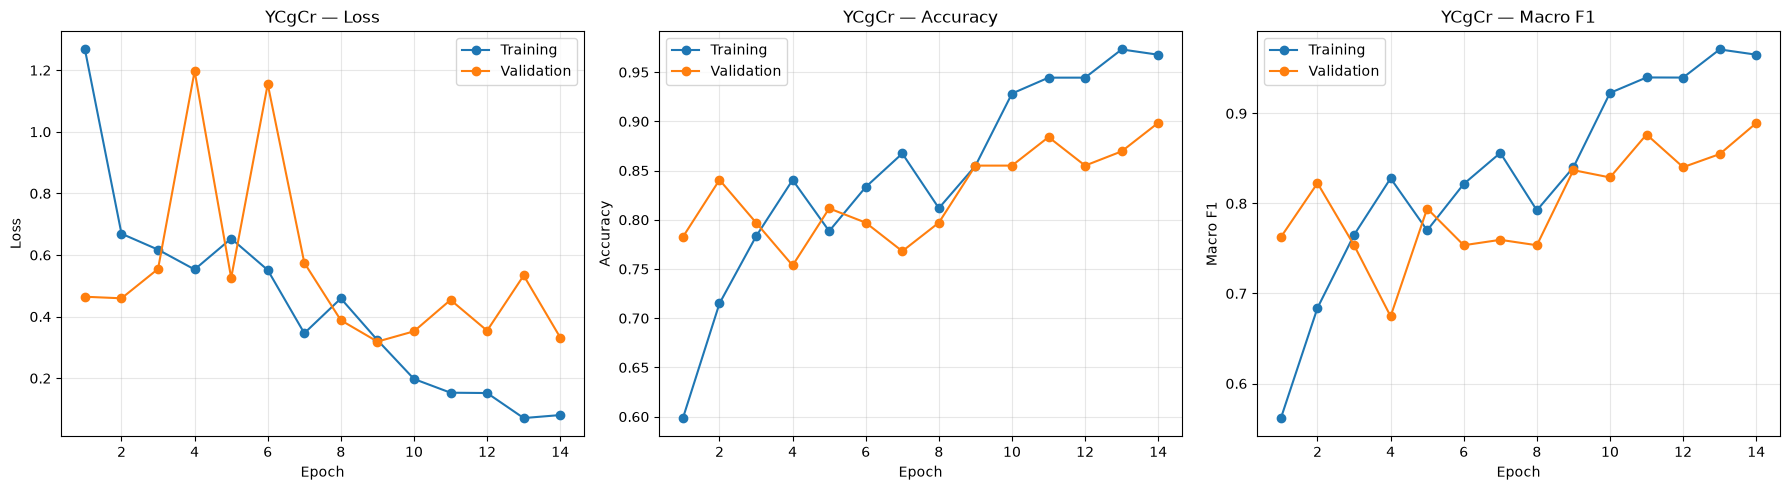

In [30]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Loss
axes[0].plot(epochs, history["train_loss"], marker="o", label="Training")
axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation")
axes[0].set_title("YCgCr — Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy
axes[1].plot(epochs, history["train_accuracy"], marker="o", label="Training")
axes[1].plot(epochs, history["val_accuracy"], marker="o", label="Validation")
axes[1].set_title("YCgCr — Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Macro F1
axes[2].plot(epochs, history["train_macro_f1"], marker="o", label="Training")
axes[2].plot(epochs, history["val_macro_f1"], marker="o", label="Validation")
axes[2].set_title("YCgCr — Macro F1")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Macro F1")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(MODEL_DIR / "vgg16_YCgCr_learning_curves.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

vgg16_test_results = {}
vgg16_test_predictions = {}

for color_space in COLOR_SPACES:

    print(f"\nEvaluating VGG16 — {color_space}")
    print("=" * 55)

    # Load the corresponding test loader
    test_loader = dataloaders[color_space]["test"]

    # Load the best checkpoint
    checkpoint_path = MODEL_DIR / f"vgg16_{color_space}_best.pth"
    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    # Initialize model and restore weights
    eval_model = build_vgg16(freeze_backbone=True)
    eval_model.load_state_dict(checkpoint["model_state_dict"])
    eval_model = eval_model.to(DEVICE)
    eval_model.eval()

    all_labels = []
    all_predictions = []
    total_loss = 0.0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = eval_model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions = torch.argmax(outputs, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    # Calculate test metrics
    test_loss = total_loss / len(test_loader.dataset)
    accuracy = accuracy_score(all_labels, all_predictions)
    precision = precision_score(
        all_labels, all_predictions, average="macro", zero_division=0
    )
    recall = recall_score(
        all_labels, all_predictions, average="macro", zero_division=0
    )
    macro_f1 = f1_score(
        all_labels, all_predictions, average="macro", zero_division=0
    )
    balanced_acc = balanced_accuracy_score(all_labels, all_predictions)
    cm = confusion_matrix(all_labels, all_predictions)

    vgg16_test_results[color_space] = {
        "test_loss": test_loss,
        "accuracy": accuracy,
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": macro_f1,
        "balanced_accuracy": balanced_acc,
        "confusion_matrix": cm,
        "best_epoch": checkpoint["epoch"],
        "best_val_loss": checkpoint["best_val_loss"]
    }

    vgg16_test_predictions[color_space] = {
        "y_true": np.array(all_labels),
        "y_pred": np.array(all_predictions)
    }

    print(f"Checkpoint epoch: {checkpoint['epoch']}")
    print(f"Test loss:          {test_loss:.4f}")
    print(f"Accuracy:           {accuracy*100:.2f}%")
    print(f"Macro precision:    {precision:.4f}")
    print(f"Macro recall:       {recall:.4f}")
    print(f"Macro F1:           {macro_f1:.4f}")
    print(f"Balanced accuracy:  {balanced_acc:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        all_labels,
        all_predictions,
        target_names=CLASS_NAMES,
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(cm)

    del eval_model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("\nAll VGG16 test evaluations completed.")


Evaluating VGG16 — RGB
Checkpoint epoch: 14
Test loss:          3.5733
Accuracy:           62.86%
Macro precision:    0.3143
Macro recall:       0.5000
Macro F1:           0.3860
Balanced accuracy:  0.5000

Classification Report:
              precision    recall  f1-score   support

        Ripe       0.00      0.00      0.00        26
      Unripe       0.63      1.00      0.77        44

    accuracy                           0.63        70
   macro avg       0.31      0.50      0.39        70
weighted avg       0.40      0.63      0.49        70

Confusion Matrix:
[[ 0 26]
 [ 0 44]]

Evaluating VGG16 — HSV
Checkpoint epoch: 11
Test loss:          0.4411
Accuracy:           80.00%
Macro precision:    0.7857
Macro recall:       0.7937
Macro F1:           0.7890
Balanced accuracy:  0.7937

Classification Report:
              precision    recall  f1-score   support

        Ripe       0.71      0.77      0.74        26
      Unripe       0.86      0.82      0.84        44

    accura

In [32]:
# Load the saved RGB checkpoint
rgb_checkpoint_path = MODEL_DIR / "vgg16_RGB_best.pth"

rgb_checkpoint = torch.load(
    rgb_checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

rgb_model = build_vgg16(freeze_backbone=True).to(DEVICE)
rgb_model.load_state_dict(rgb_checkpoint["model_state_dict"])
rgb_model.eval()

print("RGB CHECKPOINT DIAGNOSTIC")
print("=" * 55)
print("Checkpoint epoch:", rgb_checkpoint["epoch"])
print("Class mapping:", dataloaders["RGB"]["train"].dataset.class_to_idx)

for split in ["validation", "test"]:

    loader = dataloaders["RGB"][split]

    labels_all = []
    predictions_all = []
    probabilities_all = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE)

            outputs = rgb_model(images)
            probabilities = torch.softmax(outputs, dim=1)
            predictions = torch.argmax(outputs, dim=1)

            labels_all.extend(labels.numpy())
            predictions_all.extend(predictions.cpu().numpy())
            probabilities_all.extend(probabilities.cpu().numpy())

    labels_all = np.array(labels_all)
    predictions_all = np.array(predictions_all)
    probabilities_all = np.array(probabilities_all)

    print(f"\n{split.upper()} SET")
    print("-" * 40)
    print("Actual class counts:",
          np.bincount(labels_all, minlength=NUM_CLASSES))
    print("Predicted class counts:",
          np.bincount(predictions_all, minlength=NUM_CLASSES))
    print("Accuracy:", round(accuracy_score(labels_all, predictions_all), 4))
    print("Confusion matrix:")
    print(confusion_matrix(labels_all, predictions_all))

    print("Mean predicted probabilities:")
    print("Ripe:", round(probabilities_all[:, 0].mean(), 4))
    print("Unripe:", round(probabilities_all[:, 1].mean(), 4))

print("\nDiagnostic completed.")

RGB CHECKPOINT DIAGNOSTIC
Checkpoint epoch: 14
Class mapping: {'Ripe': 0, 'Unripe': 1}

VALIDATION SET
----------------------------------------
Actual class counts: [25 44]
Predicted class counts: [ 0 69]
Accuracy: 0.6377
Confusion matrix:
[[ 0 25]
 [ 0 44]]
Mean predicted probabilities:
Ripe: 0.0068
Unripe: 0.9932

TEST SET
----------------------------------------
Actual class counts: [26 44]
Predicted class counts: [ 0 70]
Accuracy: 0.6286
Confusion matrix:
[[ 0 26]
 [ 0 44]]
Mean predicted probabilities:
Ripe: 0.0045
Unripe: 0.9955

Diagnostic completed.


In [33]:
rgb_checkpoint = torch.load(
    MODEL_DIR / "vgg16_RGB_best.pth",
    map_location="cpu",
    weights_only=False
)

print("RGB CHECKPOINT METADATA")
print("=" * 45)

for key, value in rgb_checkpoint.items():
    if key != "model_state_dict" and key != "optimizer_state_dict":
        print(f"{key}: {value}")

print("\nMODEL WEIGHT DIAGNOSTICS")
print("=" * 45)

for key in [
    "classifier.6.weight",
    "classifier.6.bias"
]:
    tensor = rgb_checkpoint["model_state_dict"][key]
    print(f"\n{key}")
    print("Shape:", tuple(tensor.shape))
    print("Mean:", tensor.mean().item())
    print("Std:", tensor.std().item())
    print("Min:", tensor.min().item())
    print("Max:", tensor.max().item())

RGB CHECKPOINT METADATA
epoch: 14
phase: 2
best_val_loss: 0.32949247826700623
color_space: RGB

MODEL WEIGHT DIAGNOSTICS

classifier.6.weight
Shape: (2, 4096)
Mean: -9.48818342294544e-06
Std: 0.008440174162387848
Min: -0.02689238451421261
Max: 0.02707238309085369

classifier.6.bias
Shape: (2,)
Mean: 0.010648233816027641
Std: 0.001857216004282236
Min: 0.009334984235465527
Max: 0.01196148432791233


In [34]:
# Load the exact saved RGB checkpoint
checkpoint = torch.load(
    MODEL_DIR / "vgg16_RGB_best.pth",
    map_location=DEVICE,
    weights_only=False
)

diagnostic_model = build_vgg16(freeze_backbone=True).to(DEVICE)
diagnostic_model.load_state_dict(checkpoint["model_state_dict"])
diagnostic_model.eval()

for split in ["validation", "test"]:

    loader = dataloaders["RGB"][split]

    all_logits = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE)
            logits = diagnostic_model(images)

            all_logits.extend(logits.cpu().numpy())
            all_labels.extend(labels.numpy())

    logits = np.array(all_logits)
    labels = np.array(all_labels)

    predictions = np.argmax(logits, axis=1)
    probabilities = torch.softmax(
        torch.tensor(logits), dim=1
    ).numpy()

    print(f"\n{split.upper()} LOGIT DIAGNOSTICS")
    print("=" * 50)

    print("Mean logits:")
    print("Ripe:", logits[:, 0].mean())
    print("Unripe:", logits[:, 1].mean())

    print("\nMean probabilities:")
    print("Ripe:", probabilities[:, 0].mean())
    print("Unripe:", probabilities[:, 1].mean())

    print("\nLogit standard deviation:")
    print("Ripe:", logits[:, 0].std())
    print("Unripe:", logits[:, 1].std())

    print("\nPrediction counts:",
          np.bincount(predictions, minlength=NUM_CLASSES))

    print("Cross-entropy loss:",
          nn.CrossEntropyLoss()(
              torch.tensor(logits, dtype=torch.float32),
              torch.tensor(labels, dtype=torch.long)
          ).item())

    print("\nFirst 10 predictions:")
    print("Actual:    ", labels[:10])
    print("Predicted: ", predictions[:10])

print("\nLogit diagnostics completed.")


VALIDATION LOGIT DIAGNOSTICS
Mean logits:
Ripe: -5.292602
Unripe: 4.47338

Mean probabilities:
Ripe: 0.0067956233
Unripe: 0.9932043

Logit standard deviation:
Ripe: 2.2967641
Unripe: 1.9963691

Prediction counts: [ 0 69]
Cross-entropy loss: 4.083685398101807

First 10 predictions:
Actual:     [0 0 0 0 0 0 0 0 0 0]
Predicted:  [1 1 1 1 1 1 1 1 1 1]

TEST LOGIT DIAGNOSTICS
Mean logits:
Ripe: -4.7771945
Unripe: 4.012565

Mean probabilities:
Ripe: 0.00449154
Unripe: 0.9955085

Logit standard deviation:
Ripe: 1.8783067
Unripe: 1.6387296

Prediction counts: [ 0 70]
Cross-entropy loss: 3.57328200340271

First 10 predictions:
Actual:     [0 0 0 0 0 0 0 0 0 0]
Predicted:  [1 1 1 1 1 1 1 1 1 1]

Logit diagnostics completed.


In [35]:
import inspect

print("=" * 60)
print("1. BUILD_VGG16 FUNCTION")
print("=" * 60)
print(inspect.getsource(build_vgg16))

print("\n" + "=" * 60)
print("2. RUN_EPOCH FUNCTION")
print("=" * 60)
print(inspect.getsource(run_epoch))

print("\n" + "=" * 60)
print("3. RGB VALIDATION TRANSFORM")
print("=" * 60)
print(dataloaders["RGB"]["validation"].dataset.transform)

print("\n" + "=" * 60)
print("4. RGB TEST TRANSFORM")
print("=" * 60)
print(dataloaders["RGB"]["test"].dataset.transform)

print("\n" + "=" * 60)
print("5. CHECKPOINT FILE INFORMATION")
print("=" * 60)
print("RGB:", (MODEL_DIR / "vgg16_RGB_best.pth").stat().st_size, "bytes")
print("HSV:", (MODEL_DIR / "vgg16_HSV_best.pth").stat().st_size, "bytes")
print("YCgCr:", (MODEL_DIR / "vgg16_YCgCr_best.pth").stat().st_size, "bytes")

1. BUILD_VGG16 FUNCTION
def build_vgg16(freeze_backbone=True):

    # Load ImageNet pretrained VGG16
    model = vgg16(weights=VGG16_Weights.IMAGENET1K_V1)

    # Freeze convolutional feature extractor
    if freeze_backbone:
        for param in model.features.parameters():
            param.requires_grad = False

    # Replace final classification layer
    in_features = model.classifier[6].in_features
    model.classifier[6] = nn.Linear(in_features, NUM_CLASSES)

    return model.to(DEVICE)


2. RUN_EPOCH FUNCTION
def run_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None

    model.train() if is_training else model.eval()

    # Keep frozen feature extractor in evaluation mode
    if is_training:
        for param in model.features.parameters():
            if not param.requires_grad:
                model.features.eval()

    running_loss = 0.0
    all_labels = []
    all_predictions = []

    for images, labels in tqdm(loader, leave=False, di

In [36]:
print("RGB TRAINING TRANSFORM")
print("=" * 50)
print(dataloaders["RGB"]["train"].dataset.transform)

print("\nRGB DATASET INFORMATION")
print("=" * 50)

for split in ["train", "validation", "test"]:
    dataset = dataloaders["RGB"][split].dataset

    print(f"\n{split.upper()}")
    print("Root:", dataset.root)
    print("Number of images:", len(dataset))
    print("Class mapping:", dataset.class_to_idx)
    print("First 5 samples:")

    for path, label in dataset.samples[:5]:
        print(Path(path).name, "->", CLASS_NAMES[label])

print("\nRGB MODEL CHECKPOINT")
print("=" * 50)

print("Checkpoint epoch:", rgb_checkpoint["epoch"])
print("Checkpoint phase:", rgb_checkpoint["phase"])
print("Saved validation loss:", rgb_checkpoint["best_val_loss"])

RGB TRAINING TRANSFORM
Compose(
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=bilinear, expand=False, fill=(87, 82, 63))
    ToTensor()
    Normalize(mean=[0.3409183707365453, 0.31965236125256286, 0.246347647622037], std=[0.3073407603064623, 0.2990722908867604, 0.2818262994987366])
)

RGB DATASET INFORMATION

TRAIN
Root: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\notebooks\dataset\processed_dataset\RGB\train
Number of images: 558
Class mapping: {'Ripe': 0, 'Unripe': 1}
First 5 samples:
1.png -> Ripe
100.png -> Ripe
101.png -> Ripe
102.png -> Ripe
103.png -> Ripe

VALIDATION
Root: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\notebooks\dataset\processed_dataset\RGB\validation
Number of images: 69
Class mapping: {'Ripe': 0, 'Unripe': 1}
First 5 samples:
0.png -> Ripe
10.png -> Ripe
125.png -> Ripe
16.png -> Ripe
183.png -> Ripe

TEST
Root: c:\Users\gsama\Desktop\arecanut_research_starte

In [37]:
print("RGB CHECKPOINT — SPLIT-WISE DIAGNOSTIC")
print("=" * 60)

for split in ["train", "validation", "test"]:

    loader = dataloaders["RGB"][split]

    labels_all = []
    predictions_all = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE)
            outputs = rgb_model(images)
            predictions = torch.argmax(outputs, dim=1)

            labels_all.extend(labels.numpy())
            predictions_all.extend(predictions.cpu().numpy())

    labels_all = np.array(labels_all)
    predictions_all = np.array(predictions_all)

    print(f"\n{split.upper()}")
    print("Accuracy:",
          round(accuracy_score(labels_all, predictions_all), 4))
    print("Macro F1:",
          round(f1_score(
              labels_all, predictions_all,
              average="macro", zero_division=0
          ), 4))
    print("Actual counts:",
          np.bincount(labels_all, minlength=NUM_CLASSES))
    print("Predicted counts:",
          np.bincount(predictions_all, minlength=NUM_CLASSES))
    print("Confusion matrix:")
    print(confusion_matrix(labels_all, predictions_all))

RGB CHECKPOINT — SPLIT-WISE DIAGNOSTIC

TRAIN
Accuracy: 0.6362
Macro F1: 0.3935
Actual counts: [204 354]
Predicted counts: [  1 557]
Confusion matrix:
[[  1 203]
 [  0 354]]

VALIDATION
Accuracy: 0.6377
Macro F1: 0.3894
Actual counts: [25 44]
Predicted counts: [ 0 69]
Confusion matrix:
[[ 0 25]
 [ 0 44]]

TEST
Accuracy: 0.6286
Macro F1: 0.386
Actual counts: [26 44]
Predicted counts: [ 0 70]
Confusion matrix:
[[ 0 26]
 [ 0 44]]


In [38]:
print("RGB CHECKPOINT STATE DIAGNOSTIC")
print("=" * 55)

print("Current model device:", next(rgb_model.parameters()).device)
print("Model training mode:", rgb_model.training)

# Inspect classifier parameters
for name, param in rgb_model.classifier.named_parameters():
    print(
        name,
        "| requires_grad:", param.requires_grad,
        "| mean:", round(param.data.mean().item(), 6),
        "| std:", round(param.data.std().item(), 6)
    )

# Inspect the final classifier bias
print("\nFinal classifier bias:")
print(rgb_model.classifier[6].bias.detach().cpu())

# Compare loaded model state against checkpoint state
loaded_state = rgb_model.state_dict()
saved_state = rgb_checkpoint["model_state_dict"]

differences = {
    key: not torch.equal(loaded_state[key].cpu(), saved_state[key].cpu())
    for key in saved_state
}

print("\nCheckpoint/model state mismatches:",
      sum(differences.values()))

print("Total state tensors:", len(differences))
print("All tensors match:", not any(differences.values()))

RGB CHECKPOINT STATE DIAGNOSTIC
Current model device: cuda:0
Model training mode: False
0.weight | requires_grad: True | mean: -0.000979 | std: 0.006995
0.bias | requires_grad: True | mean: 0.005709 | std: 0.019034
3.weight | requires_grad: True | mean: -0.001582 | std: 0.010442
3.bias | requires_grad: True | mean: 0.051832 | std: 0.020047
6.weight | requires_grad: True | mean: -9e-06 | std: 0.00844
6.bias | requires_grad: True | mean: 0.010648 | std: 0.001857

Final classifier bias:
tensor([0.0120, 0.0093])

Checkpoint/model state mismatches: 0
Total state tensors: 32
All tensors match: True


In [39]:
print("CURRENT HISTORY VARIABLE")
print("=" * 50)

print("History keys:", list(history.keys()))
print("Number of training epochs:", len(history["train_loss"]))

print("\nCURRENT HISTORY SUMMARY")

for key, values in history.items():
    print(f"{key}: {len(values)} values")

print("\nRGB CHECKPOINT EPOCH:", rgb_checkpoint["epoch"])
print("RGB CHECKPOINT PHASE:", rgb_checkpoint["phase"])

CURRENT HISTORY VARIABLE
History keys: ['train_loss', 'train_accuracy', 'train_macro_f1', 'val_loss', 'val_accuracy', 'val_macro_f1', 'learning_rate']
Number of training epochs: 14

CURRENT HISTORY SUMMARY
train_loss: 14 values
train_accuracy: 14 values
train_macro_f1: 14 values
val_loss: 14 values
val_accuracy: 14 values
val_macro_f1: 14 values
learning_rate: 14 values

RGB CHECKPOINT EPOCH: 14
RGB CHECKPOINT PHASE: 2


In [40]:
print("HISTORY VARIABLES IN MEMORY")
print("=" * 55)

for name, value in globals().copy().items():
    if "history" in name.lower():
        if isinstance(value, dict):
            print(
                f"{name}:",
                len(value.get("train_loss", [])),
                "epochs"
            )
        else:
            print(f"{name}: {type(value).__name__}")

print("\nCURRENT HISTORY — VALIDATION LOSSES")
print([round(x, 4) for x in history["val_loss"]])

print("\nCURRENT HISTORY — VALIDATION ACCURACIES")
print([round(x, 4) for x in history["val_accuracy"]])

HISTORY VARIABLES IN MEMORY
history: 14 epochs

CURRENT HISTORY — VALIDATION LOSSES
[0.4645, 0.4595, 0.5548, 1.1969, 0.5256, 1.1548, 0.5748, 0.3881, 0.3189, 0.3523, 0.4543, 0.3544, 0.5335, 0.3322]

CURRENT HISTORY — VALIDATION ACCURACIES
[0.7826, 0.8406, 0.7971, 0.7536, 0.8116, 0.7971, 0.7681, 0.7971, 0.8551, 0.8551, 0.8841, 0.8551, 0.8696, 0.8986]


In [41]:
import json

notebook_path = PROJECT_DIR / "notebooks" / "04_vgg16.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook_data = json.load(f)

print("NOTEBOOK:", notebook_path)
print("=" * 65)

for i, cell in enumerate(notebook_data["cells"]):
    if cell["cell_type"] != "code":
        continue

    output_text = []

    for output in cell.get("outputs", []):
        if "text" in output:
            output_text.extend(output["text"])
        elif "data" in output and "text/plain" in output["data"]:
            output_text.extend(output["data"]["text/plain"])

    combined = "".join(output_text)

    if "RGB" in combined and ("Epoch" in combined or "Phase" in combined):
        print(f"\nCELL {i}")
        print(combined[:12000])

NOTEBOOK: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\notebooks\04_vgg16.ipynb

CELL 9
Starting VGG16 — RGB Phase 1
Epoch 01/10 | Train Loss: 1.4901 | Train Acc: 56.09% | Val Loss: 0.8170 | Val Acc: 63.77% | Val F1: 0.3894 | LR: 1.00e-03 | 8.9s | BEST MODEL SAVED
Epoch 02/10 | Train Loss: 0.7248 | Train Acc: 68.10% | Val Loss: 0.4874 | Val Acc: 81.16% | Val F1: 0.7903 | LR: 1.00e-03 | 8.1s | BEST MODEL SAVED
Epoch 03/10 | Train Loss: 0.6060 | Train Acc: 75.45% | Val Loss: 0.4789 | Val Acc: 82.61% | Val F1: 0.8118 | LR: 1.00e-03 | 8.1s | BEST MODEL SAVED
Epoch 04/10 | Train Loss: 0.5476 | Train Acc: 77.96% | Val Loss: 0.7524 | Val Acc: 78.26% | Val F1: 0.7398 | LR: 1.00e-03 | 6.2s | No improvement (1/5)
Epoch 05/10 | Train Loss: 0.5819 | Train Acc: 80.82% | Val Loss: 0.8194 | Val Acc: 75.36% | Val F1: 0.7483 | LR: 1.00e-03 | 5.8s | No improvement (2/5)
Epoch 06/10 | Train Loss: 0.6136 | Train Acc: 80.29% | Val Loss: 0.7536 | Val Acc: 76.81% | Val F1: 0.762

In [42]:
import inspect

print("TRAINING FUNCTION SOURCE")
print("=" * 70)

for name, obj in globals().copy().items():
    if callable(obj) and name in ["train_model", "train_phase"]:
        print(f"\nFunction: {name}")
        print(inspect.getsource(obj))

print("\nCHECKPOINT FILE DETAILS")
print("=" * 70)

print("Path:", RGB_CHECKPOINT_PATH if "RGB_CHECKPOINT_PATH" in globals()
      else MODEL_DIR / "vgg16_RGB_best.pth")

print("Exists:", (MODEL_DIR / "vgg16_RGB_best.pth").exists())
print("Size (MB):", round(
    (MODEL_DIR / "vgg16_RGB_best.pth").stat().st_size / (1024**2), 2
))

TRAINING FUNCTION SOURCE

CHECKPOINT FILE DETAILS
Path: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\vgg16\vgg16_RGB_best.pth
Exists: True
Size (MB): 1478.35


In [43]:
for i, cell in enumerate(notebook_data["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell.get("source", []))

    if "torch.save" in source or "best_model_state" in source:
        print(f"\n{'=' * 70}")
        print(f"CELL {i}")
        print("=" * 70)
        print(source)


CELL 8
# Training history
history = {
    "train_loss": [],
    "train_accuracy": [],
    "train_macro_f1": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": [],
    "learning_rate": []
}

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

best_model_state = None

CHECKPOINT_PATH = MODEL_DIR / "vgg16_RGB_best.pth"

print("CHECKPOINT CONFIGURATION")
print("=" * 40)
print("Checkpoint path:", CHECKPOINT_PATH)
print("Selection metric: Validation loss")
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)
print("Initial best validation loss:", best_val_loss)

CELL 9
print("Starting VGG16 — RGB Phase 1")
print("=" * 60)

for epoch in range(NUM_EPOCHS_HEAD):
    start_time = time.time()

    train_metrics = run_epoch(
        model, train_loader, criterion, optimizer
    )

    val_metrics = run_epoch(
        model, val_loader, criterion
    )

    scheduler.step(val_metrics["loss"])

    current_lr = optimizer.param_groups[0]["lr"]

    hist

In [44]:
for target_cell in [7, 10, 12]:
    cell = notebook_data["cells"][target_cell]

    print("\n" + "=" * 75)
    print(f"CELL {target_cell}")
    print("=" * 75)

    print("".join(cell.get("source", [])))


CELL 7
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE_HEAD,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

print("OPTIMIZER CONFIGURATION")
print("=" * 40)
print("Optimizer:", optimizer.__class__.__name__)
print("Phase 1 learning rate:", optimizer.param_groups[0]["lr"])
print("Weight decay:", WEIGHT_DECAY)
print("Scheduler:", scheduler.__class__.__name__)
print("Scheduler patience:", scheduler.patience)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)

CELL 10
# Restore the best Phase 1 checkpoint
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])

# Freeze all convolutional layers first
for param in model.features.parameters():
    param.requires_grad = Fal

In [45]:
for target_cell in [5, 6]:
    cell = notebook_data["cells"][target_cell]

    print("\n" + "=" * 75)
    print(f"CELL {target_cell}")
    print("=" * 75)

    print("".join(cell.get("source", [])))


CELL 5
# Training configuration
from copy import deepcopy
import time
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Phase 1: Train classifier only
for param in model.features.parameters():
    param.requires_grad = False

for param in model.classifier.parameters():
    param.requires_grad = True

print("PHASE 1 — CLASSIFIER TRAINING")
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

# Check GPU memory
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    allocated = torch.cuda.memory_allocated() / (1024 ** 3)
    reserved = torch.cuda.memory_reserved() / (1024 ** 3)

    print(f"\nGPU: {torch.cuda.get_device_name(0)}")
    print(f"Allocated memory: {allocated:.2f} GB")
    print(f"Reserved memory: {reserved:.2f} GB")

print("\nTraining configuration:")
print("Phase 1 epochs:", NUM_EPOCHS_HE

In [46]:
for target_cell in [3, 4]:
    cell = notebook_data["cells"][target_cell]

    print("\n" + "=" * 75)
    print(f"CELL {target_cell}")
    print("=" * 75)

    print("".join(cell.get("source", [])))


CELL 3
def get_transforms(color_space):

    mean = normalization_stats[color_space]["mean"]
    std = normalization_stats[color_space]["std"]

    train_transform = transforms.Compose([
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(
            degrees=10,
            interpolation=transforms.InterpolationMode.BILINEAR,
            fill=tuple(round(x * 255) for x in mean)
        ),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std)
    ])

    eval_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std)
    ])

    return train_transform, eval_transform


def build_dataloaders(color_space):

    color_dir = DATASET_DIR / color_space

    train_transform, eval_transform = get_transforms(color_space)

    train_dataset = datasets.ImageFolder(
        color_dir / "train",
        transform=train_transform
    )

    val_dataset = datasets.ImageFolder(
        color_

In [47]:
from pathlib import Path
import hashlib

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

print("RGB DATASET INTEGRITY CHECK")
print("=" * 60)

for split in ["train", "validation", "test"]:
    root = DATASET_DIR / "RGB" / split

    files = sorted(
        p for p in root.rglob("*")
        if p.is_file()
    )

    print(f"\n{split.upper()}: {len(files)} images")

    for path in files[:3]:
        print(path.relative_to(root), sha256_file(path)[:16])

RGB DATASET INTEGRITY CHECK

TRAIN: 558 images
Ripe\1.png fb0b58398be9a077
Ripe\100.png c5db3dc4770a41c3
Ripe\101.png 2c142a8a4e2443b0

VALIDATION: 69 images
Ripe\0.png ffb3399ac14ae972
Ripe\10.png f619222e6514ecf2
Ripe\125.png b5381b58cd3310f1

TEST: 70 images
Ripe\105.png a5ae9175c793abe9
Ripe\109.png 27bac7cb0c9db355
Ripe\124.png 2f082d25bb5b0f4f


In [48]:
from datetime import datetime

print("NOTEBOOK EXECUTION ORDER")
print("=" * 65)

for i, cell in enumerate(notebook_data["cells"]):
    if cell["cell_type"] != "code":
        continue

    execution_count = cell.get("execution_count")
    source = "".join(cell.get("source", []))

    if execution_count is not None:
        first_line = source.strip().split("\n")[0][:100]
        print(
            f"Execution {execution_count:>3} | "
            f"Cell {i:>3} | {first_line}"
        )

print("\nCHECKPOINT TIMESTAMPS")
print("=" * 65)

for color_space in ["RGB", "HSV", "YCgCr"]:
    path = MODEL_DIR / f"vgg16_{color_space}_best.pth"

    if path.exists():
        modified = datetime.fromtimestamp(path.stat().st_mtime)
        print(f"{color_space}: {modified}")

NOTEBOOK EXECUTION ORDER
Execution   1 | Cell   0 | import os
Execution   2 | Cell   1 | # Reproducibility
Execution   3 | Cell   2 | import json
Execution   4 | Cell   3 | def get_transforms(color_space):
Execution   5 | Cell   4 | from torchvision.models import vgg16, VGG16_Weights
Execution   6 | Cell   5 | # Training configuration
Execution   7 | Cell   6 | def run_epoch(model, loader, criterion, optimizer=None):
Execution   8 | Cell   7 | criterion = nn.CrossEntropyLoss()
Execution   9 | Cell   8 | # Training history
Execution  13 | Cell   9 | print("Starting VGG16 — RGB Phase 1")
Execution  14 | Cell  10 | # Restore the best Phase 1 checkpoint
Execution  15 | Cell  11 | print("Starting VGG16 — RGB Phase 2")
Execution  16 | Cell  12 | checkpoint = torch.load(
Execution  17 | Cell  13 | print("Available DataLoader structure:")
Execution  19 | Cell  14 | # Reset random seeds for reproducible classifier initialization
Execution  20 | Cell  15 | print("Starting VGG16 — HSV Phase 1")
E

In [50]:
cell = notebook_data["cells"][13]

print("CELL 13 SOURCE")
print("=" * 65)
print("".join(cell.get("source", [])))

print("\nCELL 13 OUTPUTS")
print("=" * 65)

for output in cell.get("outputs", []):
    if "text" in output:
        print("".join(output["text"]))

CELL 13 SOURCE
print("Available DataLoader structure:")
for key, value in dataloaders.items():
    print(f"\n{key}:")
    if isinstance(value, dict):
        for split, loader in value.items():
            print(f"  {split}: {type(loader).__name__}, "
                  f"{len(loader.dataset)} images")
    else:
        print(" ", type(value).__name__)

CELL 13 OUTPUTS
Available DataLoader structure:

RGB:
  train: DataLoader, 558 images
  validation: DataLoader, 69 images
  test: DataLoader, 70 images

HSV:
  train: DataLoader, 558 images
  validation: DataLoader, 69 images
  test: DataLoader, 70 images

YCgCr:
  train: DataLoader, 558 images
  validation: DataLoader, 69 images
  test: DataLoader, 70 images



In [51]:
print("RGB CHECKPOINT METADATA")
print("=" * 60)

for key, value in rgb_checkpoint.items():
    if key != "model_state_dict" and key != "optimizer_state_dict":
        print(f"{key}: {value}")

print("\nSELECTED BACKBONE WEIGHTS")

state = rgb_checkpoint["model_state_dict"]

for key in [
    "features.0.weight",
    "features.10.weight",
    "features.24.weight",
    "classifier.0.weight",
    "classifier.3.weight",
    "classifier.6.weight"
]:
    tensor = state[key].float()

    print(
        f"{key}:",
        "mean =", round(tensor.mean().item(), 6),
        "| std =", round(tensor.std().item(), 6),
        "| min =", round(tensor.min().item(), 6),
        "| max =", round(tensor.max().item(), 6)
    )

RGB CHECKPOINT METADATA
epoch: 14
phase: 2
best_val_loss: 0.32949247826700623
color_space: RGB

SELECTED BACKBONE WEIGHTS
features.0.weight: mean = -0.001877 | std = 0.250903 | min = -1.272565 | max = 1.073388
features.10.weight: mean = -0.00133 | std = 0.031778 | min = -0.293026 | max = 0.583614
features.24.weight: mean = -0.001602 | std = 0.017308 | min = -0.172036 | max = 0.317247
classifier.0.weight: mean = -0.000979 | std = 0.006995 | min = -0.058398 | max = 0.064244
classifier.3.weight: mean = -0.001582 | std = 0.010442 | min = -0.063678 | max = 0.070196
classifier.6.weight: mean = -9e-06 | std = 0.00844 | min = -0.026892 | max = 0.027072


In [52]:
import torch

rgb_eval_dataset = dataloaders["RGB"]["validation"].dataset

# Select one validation image
image_tensor, label = rgb_eval_dataset[0]

print("RGB INPUT DIAGNOSTIC")
print("=" * 55)

print("Image path:", rgb_eval_dataset.samples[0][0])
print("Label:", label)
print("Tensor shape:", image_tensor.shape)
print("Tensor dtype:", image_tensor.dtype)

print("\nNormalized tensor statistics:")
print("Minimum:", image_tensor.min().item())
print("Maximum:", image_tensor.max().item())
print("Mean:", image_tensor.mean().item())
print("Std:", image_tensor.std().item())

# Reconstruct approximate RGB values before normalization
mean = torch.tensor(
    normalization_stats["RGB"]["mean"]
).view(3, 1, 1)

std = torch.tensor(
    normalization_stats["RGB"]["std"]
).view(3, 1, 1)

reconstructed = image_tensor * std + mean

print("\nReconstructed RGB statistics:")
print("Minimum:", reconstructed.min().item())
print("Maximum:", reconstructed.max().item())
print("Mean:", reconstructed.mean().item())
print("Std:", reconstructed.std().item())

RGB INPUT DIAGNOSTIC
Image path: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\notebooks\dataset\processed_dataset\RGB\validation\Ripe\0.png
Label: 0
Tensor shape: torch.Size([3, 224, 224])
Tensor dtype: torch.float32

Normalized tensor statistics:
Minimum: -1.1092519760131836
Maximum: 2.674173355102539
Mean: -0.10123384743928909
Std: 0.842654824256897

Reconstructed RGB statistics:
Minimum: -1.4901161193847656e-08
Maximum: 1.0000001192092896
Mean: 0.2730424702167511
Std: 0.25799185037612915


In [53]:
rgb_model.eval()

image, true_label = dataloaders["RGB"]["validation"].dataset[0]

with torch.no_grad():
    image_batch = image.unsqueeze(0).to(DEVICE)
    logits = rgb_model(image_batch)
    probabilities = torch.softmax(logits, dim=1)[0]

predicted_label = torch.argmax(probabilities).item()

print("SINGLE IMAGE PREDICTION")
print("=" * 50)

print("Image:", dataloaders["RGB"]["validation"].dataset.samples[0][0])
print("True class:", CLASS_NAMES[true_label])
print("Predicted class:", CLASS_NAMES[predicted_label])
print("Ripe probability:", round(probabilities[0].item(), 6))
print("Unripe probability:", round(probabilities[1].item(), 6))

SINGLE IMAGE PREDICTION
Image: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\notebooks\dataset\processed_dataset\RGB\validation\Ripe\0.png
True class: Ripe
Predicted class: Unripe
Ripe probability: 0.0
Unripe probability: 1.0


In [54]:
print("MODEL-CHECKPOINT CONSISTENCY")
print("=" * 55)

checkpoint_state = rgb_checkpoint["model_state_dict"]
model_state = rgb_model.state_dict()

# Compare every parameter and buffer
mismatched = []

for key in checkpoint_state:
    if not torch.equal(model_state[key].cpu(), checkpoint_state[key].cpu()):
        mismatched.append(key)

print("Total tensors:", len(checkpoint_state))
print("Mismatched tensors:", len(mismatched))
print("First mismatches:", mismatched[:10])

# Inspect raw logits for the same image
rgb_model.eval()

image, true_label = dataloaders["RGB"]["validation"].dataset[0]

with torch.no_grad():
    logits = rgb_model(image.unsqueeze(0).to(DEVICE))[0]
    probabilities = torch.softmax(logits, dim=0)

print("\nRAW PREDICTION")
print("True label:", CLASS_NAMES[true_label])
print("Raw logits:", logits.cpu().tolist())
print("Probabilities:", probabilities.cpu().tolist())
print("Cross-entropy for this image:",
      torch.nn.functional.cross_entropy(
          logits.unsqueeze(0),
          torch.tensor([true_label], device=DEVICE)
      ).item())

MODEL-CHECKPOINT CONSISTENCY
Total tensors: 32
Mismatched tensors: 0
First mismatches: []

RAW PREDICTION
True label: Ripe
Raw logits: [-10.538554191589355, 8.924126625061035]
Probabilities: [3.527484526699709e-09, 1.0]
Cross-entropy for this image: 19.46268081665039


In [55]:
print("POSSIBLE RGB HISTORY VARIABLES")
print("=" * 55)

for name, value in globals().copy().items():
    if "history" in name.lower() and isinstance(value, dict):
        print(f"\nVariable: {name}")
        print("Keys:", list(value.keys()))

        for key, entries in value.items():
            if isinstance(entries, list) and entries:
                print(f"\n{key}:")
                print("First entry:", entries[0])
                print("Last entry:", entries[-1])

POSSIBLE RGB HISTORY VARIABLES

Variable: history
Keys: ['train_loss', 'train_accuracy', 'train_macro_f1', 'val_loss', 'val_accuracy', 'val_macro_f1', 'learning_rate']

train_loss:
First entry: 1.2674037910276843
Last entry: 0.08043590431538908

train_accuracy:
First entry: 0.5985663082437276
Last entry: 0.967741935483871

train_macro_f1:
First entry: 0.5616161616161617
Last entry: 0.9652293120638086

val_loss:
First entry: 0.46453864937243255
Last entry: 0.33218637546119484

val_accuracy:
First entry: 0.782608695652174
Last entry: 0.8985507246376812

val_macro_f1:
First entry: 0.7626691125888558
Last entry: 0.8892455858747994

learning_rate:
First entry: 0.001
Last entry: 5e-05


In [56]:
print("RGB-RELATED VARIABLES")
print("=" * 60)

for name, value in globals().copy().items():
    if "rgb" in name.lower():
        print(
            f"{name}: "
            f"type={type(value).__name__}, "
            f"shape={getattr(value, 'shape', 'N/A')}"
        )

print("\nHISTORY-RELATED VARIABLES")
print("=" * 60)

for name, value in globals().copy().items():
    if "history" in name.lower():
        print(f"{name}: {type(value).__name__}")

RGB-RELATED VARIABLES
rgb_checkpoint_path: type=WindowsPath, shape=N/A
rgb_checkpoint: type=dict, shape=N/A
rgb_model: type=VGG, shape=N/A
rgb_eval_dataset: type=ImageFolder, shape=N/A

HISTORY-RELATED VARIABLES
history: dict


In [57]:
from datetime import datetime
import shutil

backup_path = (
    MODEL_DIR /
    f"vgg16_RGB_diagnostic_backup_{datetime.now():%Y%m%d_%H%M%S}.pth"
)

shutil.copy2(rgb_checkpoint_path, backup_path)

print("Original checkpoint preserved.")
print("Backup:", backup_path)
print("Backup size:", round(backup_path.stat().st_size / (1024**2), 2), "MB")

Original checkpoint preserved.
Backup: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\vgg16\vgg16_RGB_diagnostic_backup_20261118_231646.pth
Backup size: 1478.35 MB


In [61]:
# Fresh model with ImageNet pretrained weights
set_seed(SEED)

rgb_model = build_vgg16(freeze_backbone=True)

# Fresh optimizer and scheduler
rgb_criterion = nn.CrossEntropyLoss()

rgb_optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, rgb_model.parameters()),
    lr=LEARNING_RATE_HEAD,
    weight_decay=WEIGHT_DECAY
)

rgb_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    rgb_optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

# Independent RGB training history
rgb_history = {
    "train_loss": [],
    "train_accuracy": [],
    "train_macro_f1": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_macro_f1": [],
    "learning_rate": []
}

rgb_best_val_loss = float("inf")
rgb_best_epoch = 0
rgb_epochs_without_improvement = 0

rgb_checkpoint_path = MODEL_DIR / "vgg16_RGB_retrained_best.pth"

print("Fresh RGB VGG16 initialized.")
print("Device:", DEVICE)
print("Trainable parameters:",
      sum(p.numel() for p in rgb_model.parameters() if p.requires_grad))
print("Checkpoint:", rgb_checkpoint_path)
print("History variable: rgb_history")

Fresh RGB VGG16 initialized.
Device: cuda
Trainable parameters: 119554050
Checkpoint: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\vgg16\vgg16_RGB_retrained_best.pth
History variable: rgb_history


In [62]:
for epoch in range(1, NUM_EPOCHS_HEAD + 1):

    train_metrics = run_epoch(
        rgb_model,
        dataloaders["RGB"]["train"],
        rgb_criterion,
        rgb_optimizer
    )

    val_metrics = run_epoch(
        rgb_model,
        dataloaders["RGB"]["validation"],
        rgb_criterion
    )

    rgb_scheduler.step(val_metrics["loss"])

    current_lr = rgb_optimizer.param_groups[0]["lr"]

    for key, value in [
        ("train_loss", train_metrics["loss"]),
        ("train_accuracy", train_metrics["accuracy"]),
        ("train_macro_f1", train_metrics["macro_f1"]),
        ("val_loss", val_metrics["loss"]),
        ("val_accuracy", val_metrics["accuracy"]),
        ("val_macro_f1", val_metrics["macro_f1"]),
        ("learning_rate", current_lr)
    ]:
        rgb_history[key].append(value)

    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS_HEAD} | "
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Train Acc: {train_metrics['accuracy']:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val Acc: {val_metrics['accuracy']:.4f} | "
        f"Val F1: {val_metrics['macro_f1']:.4f}"
    )

    if val_metrics["loss"] < rgb_best_val_loss:
        rgb_best_val_loss = val_metrics["loss"]
        rgb_best_epoch = epoch
        rgb_epochs_without_improvement = 0

        torch.save({
            "epoch": epoch,
            "phase": 1,
            "model_state_dict": rgb_model.state_dict(),
            "optimizer_state_dict": rgb_optimizer.state_dict(),
            "best_val_loss": rgb_best_val_loss,
            "color_space": "RGB"
        }, rgb_checkpoint_path)

        print("  Best RGB checkpoint saved.")

    else:
        rgb_epochs_without_improvement += 1

    if rgb_epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("Phase 1 early stopping triggered.")
        break

print("\nPhase 1 completed.")
print("Best epoch:", rgb_best_epoch)
print("Best validation loss:", round(rgb_best_val_loss, 4))

Epoch 01/10 | Train Loss: 1.5430 | Train Acc: 0.6613 | Val Loss: 0.3451 | Val Acc: 0.8841 | Val F1: 0.8722
  Best RGB checkpoint saved.
Epoch 02/10 | Train Loss: 0.7673 | Train Acc: 0.7634 | Val Loss: 0.3815 | Val Acc: 0.8841 | Val F1: 0.8745
Epoch 03/10 | Train Loss: 0.6173 | Train Acc: 0.8315 | Val Loss: 0.4345 | Val Acc: 0.8841 | Val F1: 0.8722
Epoch 04/10 | Train Loss: 0.6676 | Train Acc: 0.8190 | Val Loss: 0.4845 | Val Acc: 0.9130 | Val F1: 0.9042
Epoch 05/10 | Train Loss: 0.5225 | Train Acc: 0.8477 | Val Loss: 0.3190 | Val Acc: 0.8696 | Val F1: 0.8516
  Best RGB checkpoint saved.
Epoch 06/10 | Train Loss: 0.3400 | Train Acc: 0.8781 | Val Loss: 0.3391 | Val Acc: 0.8841 | Val F1: 0.8783
Epoch 07/10 | Train Loss: 0.2564 | Train Acc: 0.8889 | Val Loss: 0.4110 | Val Acc: 0.9130 | Val F1: 0.9042
Epoch 08/10 | Train Loss: 0.3948 | Train Acc: 0.8943 | Val Loss: 0.3900 | Val Acc: 0.8986 | Val F1: 0.8928
Epoch 09/10 | Train Loss: 0.1626 | Train Acc: 0.9337 | Val Loss: 0.4496 | Val Acc: 0.8

In [63]:
checkpoint = torch.load(
    rgb_checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

rgb_model.load_state_dict(checkpoint["model_state_dict"])

# Freeze the complete feature extractor first
for param in rgb_model.features.parameters():
    param.requires_grad = False

# Unfreeze the final feature blocks
for param in rgb_model.features[24:].parameters():
    param.requires_grad = True

# Keep classifier trainable
for param in rgb_model.classifier.parameters():
    param.requires_grad = True

rgb_optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, rgb_model.parameters()),
    lr=LEARNING_RATE_FINETUNE,
    weight_decay=WEIGHT_DECAY
)

rgb_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    rgb_optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7
)

rgb_best_val_loss = checkpoint["best_val_loss"]
rgb_best_epoch = checkpoint["epoch"]
rgb_epochs_without_improvement = 0

print("RGB Phase 1 checkpoint restored.")
print("Restored epoch:", rgb_best_epoch)
print("Restored validation loss:", round(rgb_best_val_loss, 4))

print("\nTrainable parameters:",
      sum(p.numel() for p in rgb_model.parameters() if p.requires_grad))

print("Frozen parameters:",
      sum(p.numel() for p in rgb_model.parameters() if not p.requires_grad))

RGB Phase 1 checkpoint restored.
Restored epoch: 5
Restored validation loss: 0.319

Trainable parameters: 126633474
Frozen parameters: 7635264


In [64]:
for epoch in range(1, NUM_EPOCHS_FINETUNE + 1):

    train_metrics = run_epoch(
        rgb_model,
        dataloaders["RGB"]["train"],
        rgb_criterion,
        rgb_optimizer
    )

    val_metrics = run_epoch(
        rgb_model,
        dataloaders["RGB"]["validation"],
        rgb_criterion
    )

    rgb_scheduler.step(val_metrics["loss"])

    current_lr = rgb_optimizer.param_groups[0]["lr"]
    total_epoch = NUM_EPOCHS_HEAD + epoch

    for key, value in [
        ("train_loss", train_metrics["loss"]),
        ("train_accuracy", train_metrics["accuracy"]),
        ("train_macro_f1", train_metrics["macro_f1"]),
        ("val_loss", val_metrics["loss"]),
        ("val_accuracy", val_metrics["accuracy"]),
        ("val_macro_f1", val_metrics["macro_f1"]),
        ("learning_rate", current_lr)
    ]:
        rgb_history[key].append(value)

    print(
        f"Epoch {total_epoch:02d}/{TOTAL_MAX_EPOCHS} | "
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Train Acc: {train_metrics['accuracy']:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val Acc: {val_metrics['accuracy']:.4f} | "
        f"Val F1: {val_metrics['macro_f1']:.4f}"
    )

    if val_metrics["loss"] < rgb_best_val_loss:
        rgb_best_val_loss = val_metrics["loss"]
        rgb_best_epoch = total_epoch
        rgb_epochs_without_improvement = 0

        torch.save({
            "epoch": total_epoch,
            "phase": 2,
            "model_state_dict": rgb_model.state_dict(),
            "optimizer_state_dict": rgb_optimizer.state_dict(),
            "best_val_loss": rgb_best_val_loss,
            "color_space": "RGB"
        }, rgb_checkpoint_path)

        print("  Best RGB checkpoint saved.")

    else:
        rgb_epochs_without_improvement += 1

    if rgb_epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("Phase 2 early stopping triggered.")
        break

print("\nRGB Phase 2 completed.")
print("Best epoch:", rgb_best_epoch)
print("Best validation loss:", round(rgb_best_val_loss, 4))

Epoch 11/50 | Train Loss: 0.3545 | Train Acc: 0.8584 | Val Loss: 0.3821 | Val Acc: 0.9130 | Val F1: 0.9074
Epoch 12/50 | Train Loss: 0.1745 | Train Acc: 0.9319 | Val Loss: 0.2286 | Val Acc: 0.9275 | Val F1: 0.9193
  Best RGB checkpoint saved.
Epoch 13/50 | Train Loss: 0.1298 | Train Acc: 0.9391 | Val Loss: 0.2914 | Val Acc: 0.9130 | Val F1: 0.9074
Epoch 14/50 | Train Loss: 0.1533 | Train Acc: 0.9444 | Val Loss: 0.2585 | Val Acc: 0.9130 | Val F1: 0.9059
Epoch 15/50 | Train Loss: 0.1088 | Train Acc: 0.9534 | Val Loss: 0.3593 | Val Acc: 0.8696 | Val F1: 0.8640
Epoch 16/50 | Train Loss: 0.0493 | Train Acc: 0.9803 | Val Loss: 0.2584 | Val Acc: 0.9275 | Val F1: 0.9209
Epoch 17/50 | Train Loss: 0.0339 | Train Acc: 0.9839 | Val Loss: 0.3544 | Val Acc: 0.9130 | Val F1: 0.9042
Phase 2 early stopping triggered.

RGB Phase 2 completed.
Best epoch: 12
Best validation loss: 0.2286


In [65]:
rgb_checkpoint = torch.load(
    rgb_checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)

rgb_model.load_state_dict(rgb_checkpoint["model_state_dict"])
rgb_model.eval()

rgb_val_metrics = run_epoch(
    rgb_model,
    dataloaders["RGB"]["validation"],
    rgb_criterion
)

print("RGB CHECKPOINT VERIFICATION")
print("=" * 50)
print("Saved epoch:", rgb_checkpoint["epoch"])
print("Saved validation loss:", rgb_checkpoint["best_val_loss"])
print("Re-evaluated validation loss:", rgb_val_metrics["loss"])
print("Re-evaluated validation accuracy:", rgb_val_metrics["accuracy"])
print("Re-evaluated validation macro F1:", rgb_val_metrics["macro_f1"])

RGB CHECKPOINT VERIFICATION
Saved epoch: 12
Saved validation loss: 0.22857756772335025
Re-evaluated validation loss: 0.22857756772335025
Re-evaluated validation accuracy: 0.927536231884058
Re-evaluated validation macro F1: 0.9193359831657704


In [66]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

rgb_test_metrics = run_epoch(
    rgb_model,
    dataloaders["RGB"]["test"],
    rgb_criterion
)

all_labels = []
all_predictions = []

rgb_model.eval()

with torch.no_grad():
    for images, labels in dataloaders["RGB"]["test"]:
        images = images.to(DEVICE)
        outputs = rgb_model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

rgb_test_cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1]
)

print("RGB VGG16 — FINAL TEST RESULTS")
print("=" * 55)
print(f"Test Loss: {rgb_test_metrics['loss']:.4f}")
print(f"Accuracy: {accuracy_score(all_labels, all_predictions):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(all_labels, all_predictions):.4f}")
print(f"Macro Precision: {precision_score(all_labels, all_predictions, average='macro'):.4f}")
print(f"Macro Recall: {recall_score(all_labels, all_predictions, average='macro'):.4f}")
print(f"Macro F1: {f1_score(all_labels, all_predictions, average='macro'):.4f}")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=CLASS_NAMES,
    zero_division=0
))

print("Confusion Matrix:")
print(rgb_test_cm)

RGB VGG16 — FINAL TEST RESULTS
Test Loss: 0.2408
Accuracy: 0.8857
Balanced Accuracy: 0.8619
Macro Precision: 0.8920
Macro Recall: 0.8619
Macro F1: 0.8732

Classification Report:
              precision    recall  f1-score   support

        Ripe       0.91      0.77      0.83        26
      Unripe       0.88      0.95      0.91        44

    accuracy                           0.89        70
   macro avg       0.89      0.86      0.87        70
weighted avg       0.89      0.89      0.88        70

Confusion Matrix:
[[20  6]
 [ 2 42]]


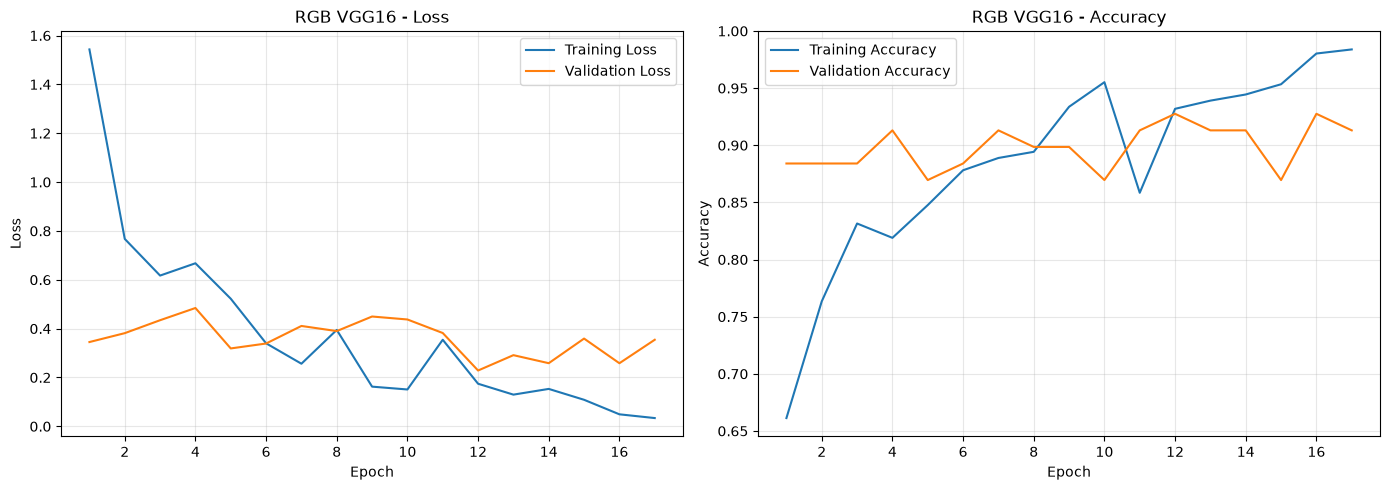

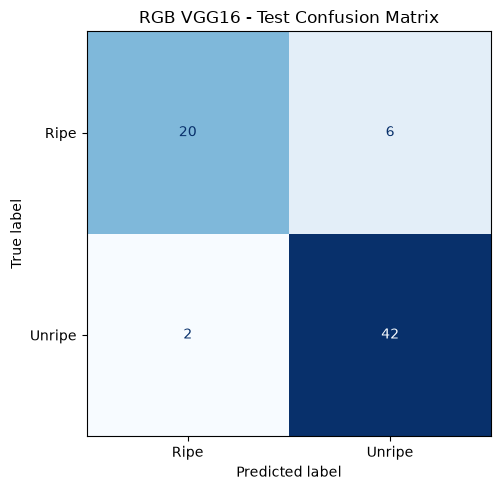

RGB experiment artifacts saved successfully.

Saved files:
vgg16_RGB_best.pth
vgg16_RGB_classification_report.json
vgg16_RGB_confusion_matrix.png
vgg16_RGB_diagnostic_backup_20261118_231646.pth
vgg16_RGB_final_results.csv
vgg16_RGB_learning_curves.png
vgg16_RGB_retrained_best.pth
vgg16_RGB_training_history.csv


In [67]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# 1. Save final test metrics
rgb_final_results = {
    "model": "VGG16",
    "color_space": "RGB",
    "best_epoch": rgb_checkpoint["epoch"],
    "best_validation_loss": rgb_checkpoint["best_val_loss"],
    "test_loss": rgb_test_metrics["loss"],
    "accuracy": accuracy_score(all_labels, all_predictions),
    "balanced_accuracy": balanced_accuracy_score(all_labels, all_predictions),
    "macro_precision": precision_score(all_labels, all_predictions, average="macro"),
    "macro_recall": recall_score(all_labels, all_predictions, average="macro"),
    "macro_f1": f1_score(all_labels, all_predictions, average="macro")
}

pd.DataFrame([rgb_final_results]).to_csv(
    MODEL_DIR / "vgg16_RGB_final_results.csv",
    index=False
)

# 2. Save training history
pd.DataFrame(rgb_history).to_csv(
    MODEL_DIR / "vgg16_RGB_training_history.csv",
    index_label="epoch"
)

# 3. Save classification report
rgb_report = classification_report(
    all_labels,
    all_predictions,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

with open(MODEL_DIR / "vgg16_RGB_classification_report.json", "w") as f:
    json.dump(rgb_report, f, indent=4)

# 4. Save learning curves
epochs = range(1, len(rgb_history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, rgb_history["train_loss"], label="Training Loss")
axes[0].plot(epochs, rgb_history["val_loss"], label="Validation Loss")
axes[0].set_title("RGB VGG16 - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, rgb_history["train_accuracy"], label="Training Accuracy")
axes[1].plot(epochs, rgb_history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("RGB VGG16 - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(MODEL_DIR / "vgg16_RGB_learning_curves.png", dpi=300)
plt.show()

# 5. Save confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=rgb_test_cm,
    display_labels=CLASS_NAMES
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("RGB VGG16 - Test Confusion Matrix")
plt.tight_layout()
plt.savefig(MODEL_DIR / "vgg16_RGB_confusion_matrix.png", dpi=300)
plt.show()

print("RGB experiment artifacts saved successfully.")
print("\nSaved files:")
for path in sorted(MODEL_DIR.glob("vgg16_RGB_*")):
    print(path.name)

All histories verified.
Saving graphs to: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\vgg16\graphs


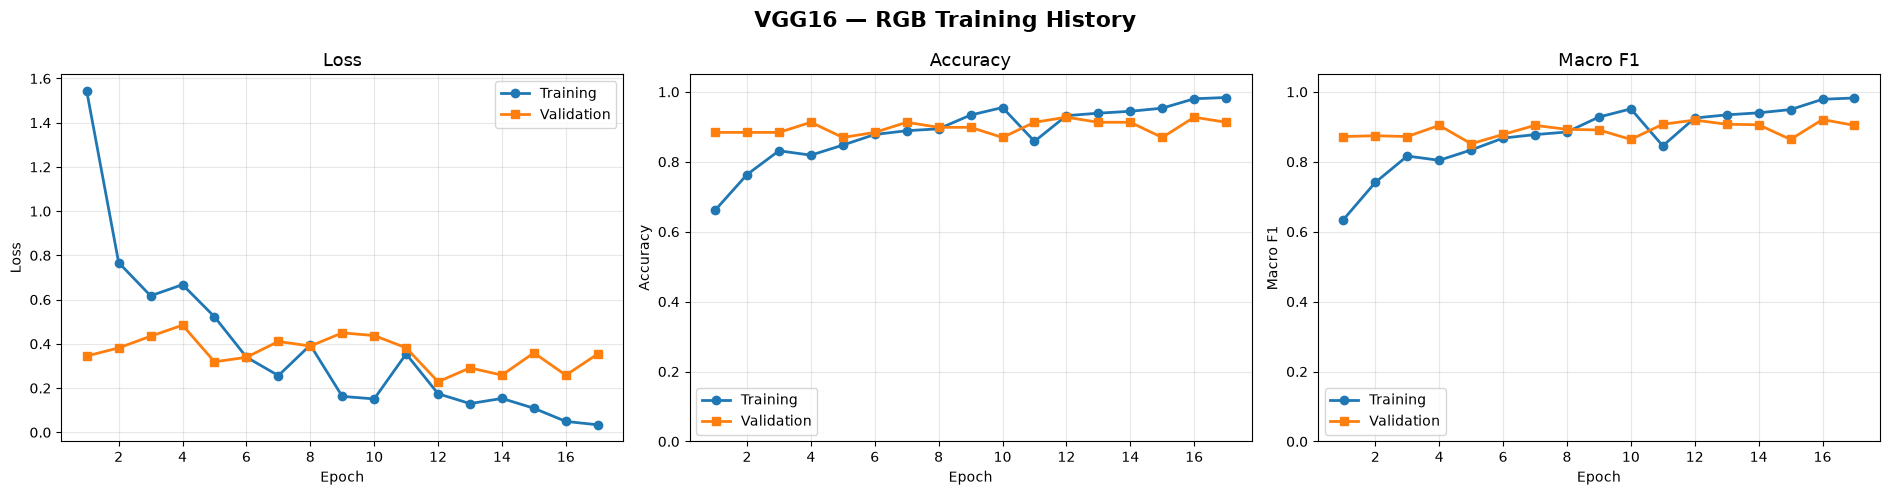

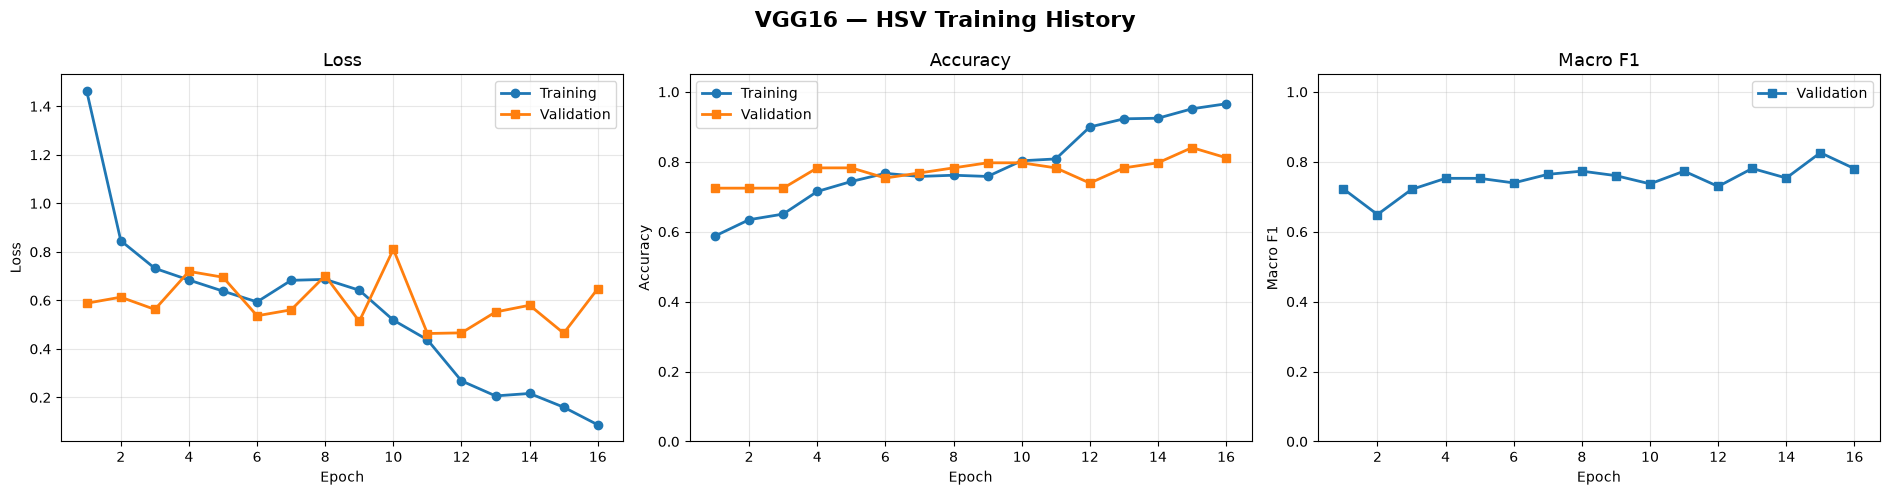

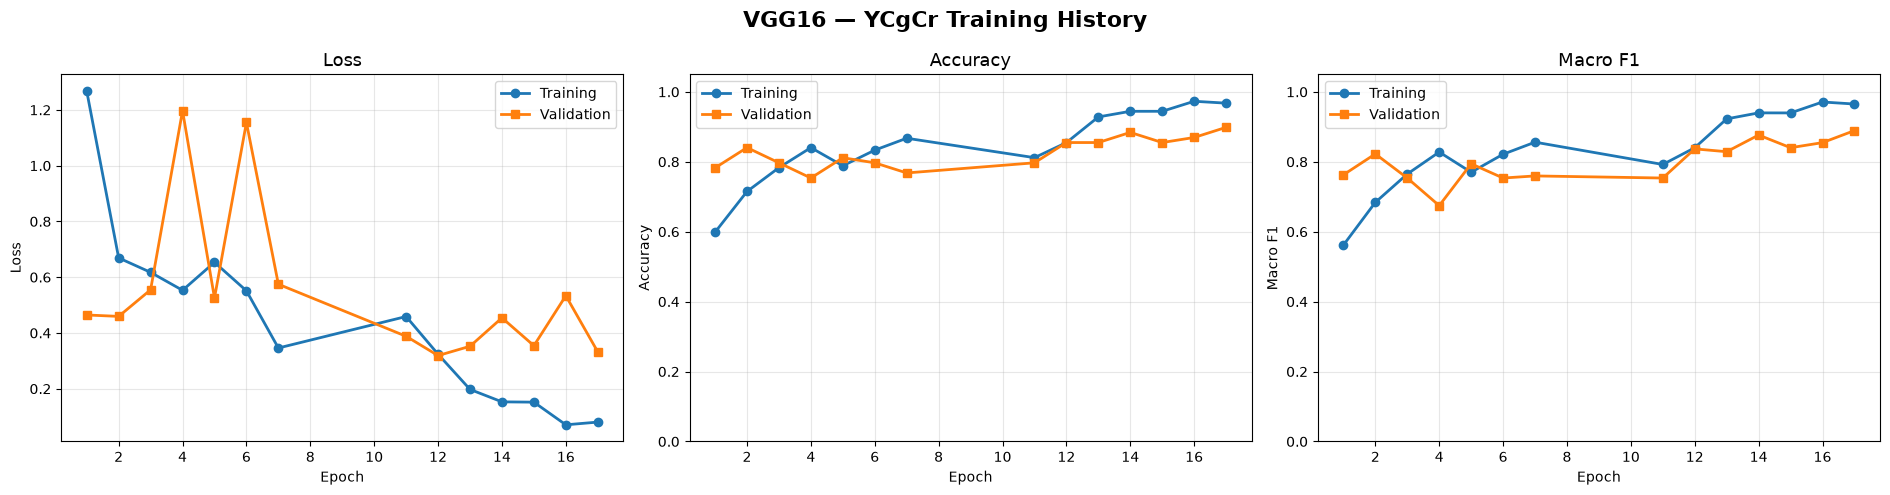

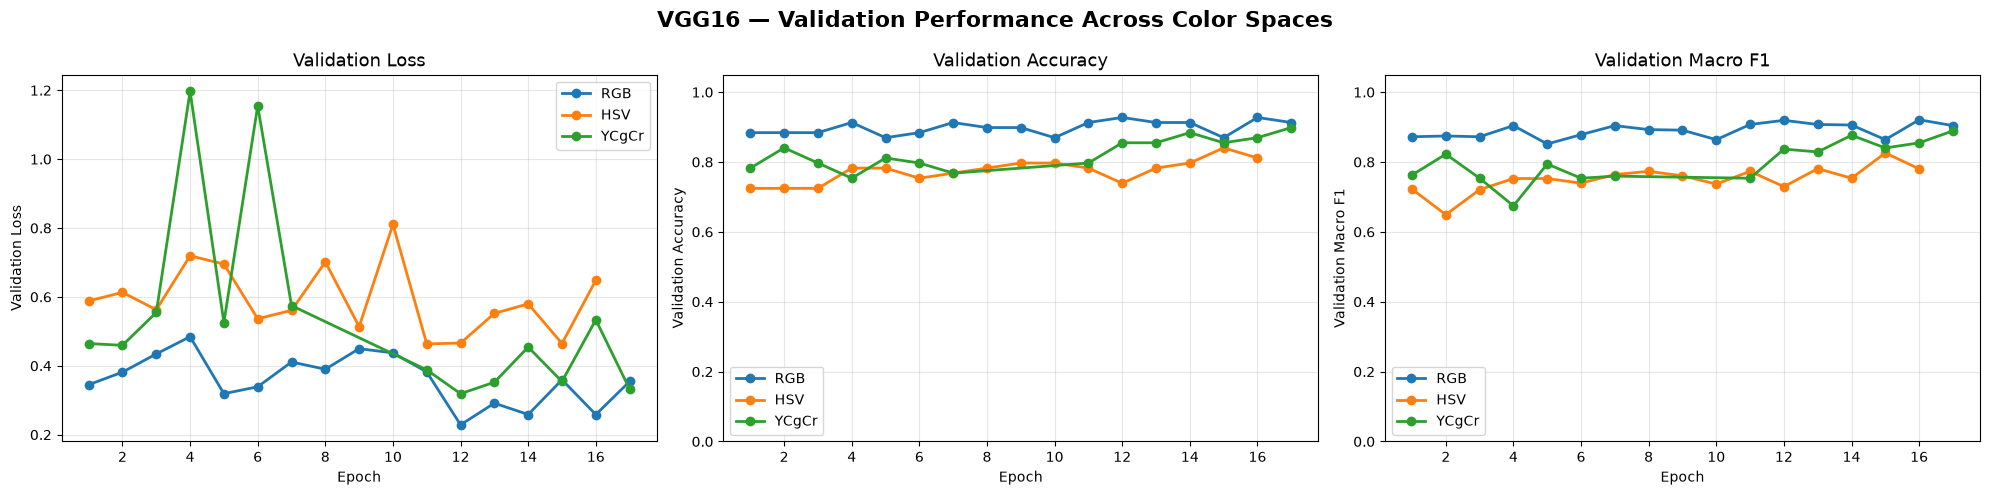

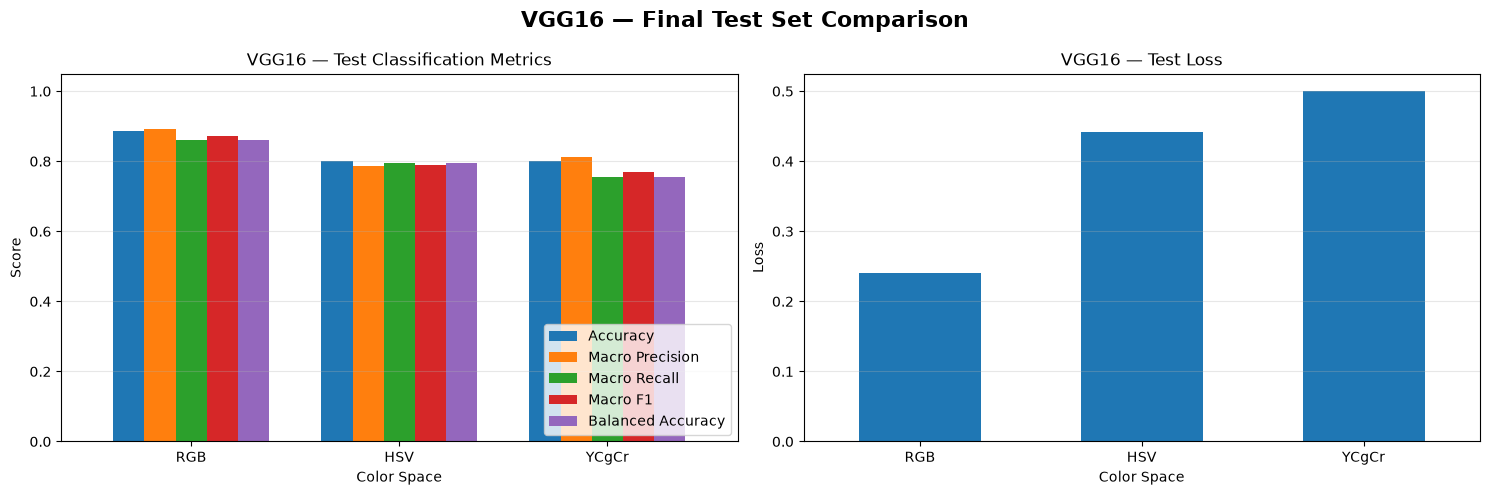

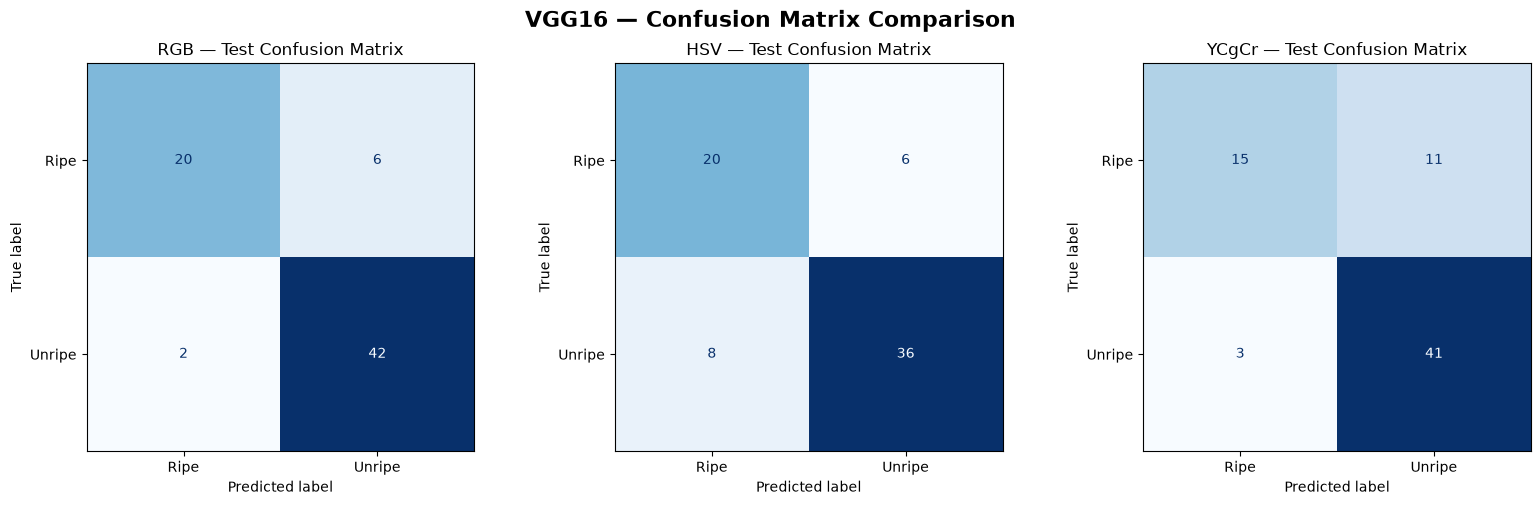


VGG16 FINAL TEST RESULTS


,Test Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Balanced Accuracy
Color Space,,,,,,
RGB,0.2408,88.57,89.20,86.19,87.32,86.19
HSV,0.4411,80.00,78.57,79.37,78.90,79.37
YCgCr,0.5000,80.00,81.09,75.44,76.80,75.44



VGG16 GRAPH GENERATION COMPLETED
Saved at: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\vgg16\graphs


In [80]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import ConfusionMatrixDisplay

# ============================================================
# 1. CONFIGURATION
# ============================================================

histories = {
    "RGB": rgb_history,
    "HSV": hsv_history,
    "YCgCr": ycgcr_history
}

# Actual recorded epoch numbers, preserving phase boundaries
epoch_numbers = {
    "RGB": list(range(1, 18)),
    "HSV": list(range(1, 17)),
    "YCgCr": list(range(1, 8)) + list(range(11, 18))
}

# Test results from the completed VGG16 evaluations
test_results = pd.DataFrame([
    {
        "Color Space": "RGB",
        "Test Loss": 0.2408,
        "Accuracy": 0.8857,
        "Macro Precision": 0.8920,
        "Macro Recall": 0.8619,
        "Macro F1": 0.8732,
        "Balanced Accuracy": 0.8619
    },
    {
        "Color Space": "HSV",
        "Test Loss": 0.4411,
        "Accuracy": 0.8000,
        "Macro Precision": 0.7857,
        "Macro Recall": 0.7937,
        "Macro F1": 0.7890,
        "Balanced Accuracy": 0.7937
    },
    {
        "Color Space": "YCgCr",
        "Test Loss": 0.5000,
        "Accuracy": 0.8000,
        "Macro Precision": 0.8109,
        "Macro Recall": 0.7544,
        "Macro F1": 0.7680,
        "Balanced Accuracy": 0.7544
    }
]).set_index("Color Space")

confusion_matrices = {
    "RGB": np.array([[20, 6], [2, 42]]),
    "HSV": np.array([[20, 6], [8, 36]]),
    "YCgCr": np.array([[15, 11], [3, 41]])
}

# Save location
GRAPH_DIR = MODEL_DIR / "graphs"
GRAPH_DIR.mkdir(parents=True, exist_ok=True)

# Validate history lengths
for name, hist in histories.items():
    assert len(hist["train_loss"]) == len(epoch_numbers[name]), (
        f"{name}: history and epoch-number lengths do not match"
    )

print("All histories verified.")
print("Saving graphs to:", GRAPH_DIR)


# ============================================================
# 2. INDIVIDUAL TRAINING CURVES — ROBUST VERSION
# ============================================================

metrics = [
    ("loss", "Loss"),
    ("accuracy", "Accuracy"),
    ("macro_f1", "Macro F1")
]

for color_space, hist in histories.items():

    epochs = epoch_numbers[color_space]

    fig, axes = plt.subplots(1, 3, figsize=(19, 5))

    for ax, (metric, title) in zip(axes, metrics):

        train_key = f"train_{metric}"
        val_key = f"val_{metric}"

        # Plot training metric only if genuinely available
        if train_key in hist:
            ax.plot(
                epochs[:len(hist[train_key])],
                hist[train_key],
                marker="o",
                linewidth=2,
                label="Training"
            )

        # Plot validation metric if available
        if val_key in hist:
            ax.plot(
                epochs[:len(hist[val_key])],
                hist[val_key],
                marker="s",
                linewidth=2,
                label="Validation"
            )

        ax.set_title(title, fontsize=13)
        ax.set_xlabel("Epoch")
        ax.set_ylabel(title)
        ax.grid(alpha=0.3)

        if metric != "loss":
            ax.set_ylim(0, 1.05)

        ax.legend()

    fig.suptitle(
        f"VGG16 — {color_space} Training History",
        fontsize=16,
        fontweight="bold"
    )

    plt.tight_layout()

    fig.savefig(
        GRAPH_DIR / f"vgg16_{color_space}_training_history.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# ============================================================
# 3. COMBINED VALIDATION CURVES
# ============================================================

combined_metrics = [
    ("val_loss", "Validation Loss"),
    ("val_accuracy", "Validation Accuracy"),
    ("val_macro_f1", "Validation Macro F1")
]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for ax, (metric, title) in zip(axes, combined_metrics):

    for color_space, hist in histories.items():

        ax.plot(
            epoch_numbers[color_space],
            hist[metric],
            marker="o",
            linewidth=2,
            label=color_space
        )

    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)

    if metric != "val_loss":
        ax.set_ylim(0, 1.05)

    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle(
    "VGG16 — Validation Performance Across Color Spaces",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

fig.savefig(
    GRAPH_DIR / "vgg16_combined_validation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 4. TEST PERFORMANCE COMPARISON
# ============================================================

plot_metrics = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Balanced Accuracy"
]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

test_results[plot_metrics].plot(
    kind="bar",
    ax=axes[0],
    width=0.75
)

axes[0].set_title("VGG16 — Test Classification Metrics")
axes[0].set_ylabel("Score")
axes[0].set_xlabel("Color Space")
axes[0].set_ylim(0, 1.05)
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", alpha=0.3)
axes[0].legend(loc="lower right")

test_results["Test Loss"].plot(
    kind="bar",
    ax=axes[1],
    width=0.55
)

axes[1].set_title("VGG16 — Test Loss")
axes[1].set_ylabel("Loss")
axes[1].set_xlabel("Color Space")
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", alpha=0.3)

fig.suptitle(
    "VGG16 — Final Test Set Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

fig.savefig(
    GRAPH_DIR / "vgg16_test_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 5. CONFUSION MATRICES
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (color_space, cm) in zip(
    axes, confusion_matrices.items()
):

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Ripe", "Unripe"]
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(f"{color_space} — Test Confusion Matrix")

fig.suptitle(
    "VGG16 — Confusion Matrix Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

fig.savefig(
    GRAPH_DIR / "vgg16_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# FINAL RESULTS TABLE
# ============================================================

from IPython.display import display as show_table

print("\nVGG16 FINAL TEST RESULTS")
print("=" * 80)

formatted_results = test_results.copy()

for col in [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1",
    "Balanced Accuracy"
]:
    formatted_results[col] = (
        formatted_results[col] * 100
    ).round(2)

formatted_results["Test Loss"] = (
    formatted_results["Test Loss"].round(4)
)

show_table(formatted_results)

test_results.to_csv(
    GRAPH_DIR / "vgg16_final_test_results.csv"
)

print("\nVGG16 GRAPH GENERATION COMPLETED")
print("Saved at:", GRAPH_DIR)


In [81]:

# ============================================================
# VGG16 — RESEARCH CONCLUSION & KEY FINDINGS
# ============================================================

from IPython.display import display, Markdown

# Extract results
best_accuracy_space = test_results["Accuracy"].idxmax()
best_f1_space = test_results["Macro F1"].idxmax()
lowest_loss_space = test_results["Test Loss"].idxmin()

best_accuracy = test_results.loc[best_accuracy_space, "Accuracy"] * 100
best_f1 = test_results.loc[best_f1_space, "Macro F1"]
lowest_loss = test_results.loc[lowest_loss_space, "Test Loss"]

# Validation checkpoint information
best_validation = {
    "RGB": {"epoch": 12, "loss": 0.2286},
    "HSV": {"epoch": 11, "loss": 0.4634},
    "YCgCr": {"epoch": 12, "loss": 0.3189}
}

# Build conclusion
conclusion = f"""
# VGG16 — Experimental Conclusion

## 1. Overall Performance

The VGG16 transfer-learning model was evaluated using three
color-space representations: RGB, HSV, and YCgCr.

| Color Space | Test Accuracy | Macro F1 | Test Loss |
|:------------|--------------:|---------:|----------:|
| RGB | 88.57% | 0.8732 | 0.2408 |
| HSV | 80.00% | 0.7890 | 0.4411 |
| YCgCr | 80.00% | 0.7680 | 0.5000 |

## 2. Key Findings

- **RGB:** Achieved the highest observed test accuracy
  ({best_accuracy:.2f}%) and macro F1 ({test_results.loc[best_f1_space, 'Macro F1']:.4f}).

- **HSV:** Achieved 80.00% test accuracy, with a macro F1
  score of 0.7890.

- **YCgCr:** Achieved 80.00% test accuracy, with a macro F1
  score of 0.7680.

- RGB also recorded the lowest test loss ({lowest_loss:.4f}).

## 3. Validation Checkpoint Selection

The best checkpoints were selected using validation loss:

| Color Space | Best Epoch | Best Validation Loss |
|:------------|-----------:|---------------------:|
| RGB | 12 | 0.2286 |
| HSV | 11 | 0.4634 |
| YCgCr | 12 | 0.3189 |

## 4. Research Interpretation

Under the current experimental setup, RGB provided the
strongest overall VGG16 classification performance.

HSV and YCgCr did not outperform RGB on the observed test
accuracy or macro F1 metrics.

These findings suggest that the RGB representation was
more effective for this particular dataset and experimental
configuration. They do not establish that RGB is universally
superior to alternative color spaces.

## 5. Limitations

- The test set contains only 70 images.
- Performance differences require further statistical validation.
- Results are based on one grouped train-validation-test split.
- External field validation under varying illumination,
  occlusion, and background conditions remains necessary.

## 6. Final Conclusion

Among the three evaluated color-space representations,
**VGG16 with RGB input achieved the strongest observed
classification performance**, recording 88.57% test accuracy
and 0.8732 macro F1.

Further evaluation using repeated grouped splits, confidence
intervals, and independent field data is required before
making broader generalization claims.
"""

display(Markdown(conclusion))

# Save conclusion as Markdown
conclusion_path = GRAPH_DIR / "vgg16_research_conclusion.md"

conclusion_path.write_text(
    conclusion,
    encoding="utf-8"
)

print("\nConclusion saved to:", conclusion_path)



# VGG16 — Experimental Conclusion

## 1. Overall Performance

The VGG16 transfer-learning model was evaluated using three
color-space representations: RGB, HSV, and YCgCr.

| Color Space | Test Accuracy | Macro F1 | Test Loss |
|:------------|--------------:|---------:|----------:|
| RGB | 88.57% | 0.8732 | 0.2408 |
| HSV | 80.00% | 0.7890 | 0.4411 |
| YCgCr | 80.00% | 0.7680 | 0.5000 |

## 2. Key Findings

- **RGB:** Achieved the highest observed test accuracy
  (88.57%) and macro F1 (0.8732).

- **HSV:** Achieved 80.00% test accuracy, with a macro F1
  score of 0.7890.

- **YCgCr:** Achieved 80.00% test accuracy, with a macro F1
  score of 0.7680.

- RGB also recorded the lowest test loss (0.2408).

## 3. Validation Checkpoint Selection

The best checkpoints were selected using validation loss:

| Color Space | Best Epoch | Best Validation Loss |
|:------------|-----------:|---------------------:|
| RGB | 12 | 0.2286 |
| HSV | 11 | 0.4634 |
| YCgCr | 12 | 0.3189 |

## 4. Research Interpretation

Under the current experimental setup, RGB provided the
strongest overall VGG16 classification performance.

HSV and YCgCr did not outperform RGB on the observed test
accuracy or macro F1 metrics.

These findings suggest that the RGB representation was
more effective for this particular dataset and experimental
configuration. They do not establish that RGB is universally
superior to alternative color spaces.

## 5. Limitations

- The test set contains only 70 images.
- Performance differences require further statistical validation.
- Results are based on one grouped train-validation-test split.
- External field validation under varying illumination,
  occlusion, and background conditions remains necessary.

## 6. Final Conclusion

Among the three evaluated color-space representations,
**VGG16 with RGB input achieved the strongest observed
classification performance**, recording 88.57% test accuracy
and 0.8732 macro F1.

Further evaluation using repeated grouped splits, confidence
intervals, and independent field data is required before
making broader generalization claims.



Conclusion saved to: c:\Users\gsama\Desktop\arecanut_research_starter\arecanut_research_starter\models\vgg16\graphs\vgg16_research_conclusion.md
